COMMON IMPORTS AND SETUP

In [1]:
# =========================
# PART 0: COMMON IMPORTS AND SETUP
# =========================

import random
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist, cifar10, cifar100
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from PIL import Image, ImageOps
from google.colab import drive

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


**MNIST Without Attention**  
The following model is a standard CNN for MNIST.

In [2]:
# =========================
# MODEL 1: MNIST CNN WITHOUT ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = mnist.load_data()

print("MNIST Training Images Shape:", x_train_mnist.shape)
print("MNIST Training Labels Shape:", y_train_mnist.shape)
print("MNIST Official Test Images Shape:", x_test_mnist.shape)
print("MNIST Official Test Labels Shape:", y_test_mnist.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST Training Images Shape: (60000, 28, 28)
MNIST Training Labels Shape: (60000,)
MNIST Official Test Images Shape: (10000, 28, 28)
MNIST Official Test Labels Shape: (10000,)


In [3]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

# Reshape because CNN expects channel dimension: 28x28x1
x_train_mnist = x_train_mnist.reshape(-1, 28, 28, 1)
x_test_mnist = x_test_mnist.reshape(-1, 28, 28, 1)

# Normalize pixel values from 0-255 to 0-1
x_train_mnist = x_train_mnist.astype("float32") / 255.0
x_test_mnist = x_test_mnist.astype("float32") / 255.0

print("After preprocessing:")
print("MNIST Training Images Shape:", x_train_mnist.shape)
print("MNIST Official Test Images Shape:", x_test_mnist.shape)
print("Minimum Pixel Value:", x_train_mnist.min())
print("Maximum Pixel Value:", x_train_mnist.max())

After preprocessing:
MNIST Training Images Shape: (60000, 28, 28, 1)
MNIST Official Test Images Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [4]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_mnist = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9"
]

In [5]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# CNN WITHOUT ATTENTION
# =========================

input_shape_mnist = (28, 28, 1)
num_classes_mnist = 10

inputs = tf.keras.Input(shape=input_shape_mnist)

x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)

# Helps reduce overfitting
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes_mnist, activation="softmax")(x)

model_mnist_cnn = models.Model(inputs=inputs, outputs=outputs)

model_mnist_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mnist_cnn.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,514 (240.29 KB)

 Trainable params: 61,514 (240.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING
# =========================

early_stopping_mnist_cnn = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_mnist_cnn = model_mnist_cnn.fit(
    x_train_mnist,
    y_train_mnist,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_mnist_cnn],
    verbose=1
)

# Get final training and validation accuracy
final_training_accuracy_mnist_cnn = history_mnist_cnn.history["accuracy"][-1]
final_validation_accuracy_mnist_cnn = history_mnist_cnn.history["val_accuracy"][-1]

print("Final Training Accuracy:", final_training_accuracy_mnist_cnn)
print("Final Validation Accuracy:", final_validation_accuracy_mnist_cnn)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 72s 93ms/step - accuracy: 0.9220 - loss: 0.2520 - val_accuracy: 0.9827 - val_loss: 0.0623
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 91ms/step - accuracy: 0.9776 - loss: 0.0717 - val_accuracy: 0.9875 - val_loss: 0.0446
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 98ms/step - accuracy: 0.9835 - loss: 0.0528 - val_accuracy: 0.9865 - val_loss: 0.0440
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 67s 90ms/step - accuracy: 0.9855 - loss: 0.0439 - val_accuracy: 0.9908 - val_loss: 0.0333
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 92ms/step - accuracy: 0.9885 - loss: 0.0364 - val_accuracy: 0.9912 - val_loss: 0.0317
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 68s 90ms/step - accuracy: 0.9895 - loss: 0.0322 - val_accuracy: 0.9911 - val_loss: 0.0333
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 67s 90ms/step - accuracy: 0.9910 - loss: 0.0280 - val_accuracy: 0.9921 - val_loss: 0.0284
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 92ms/step - accuracy: 0.9926 - loss: 0.0231 - 

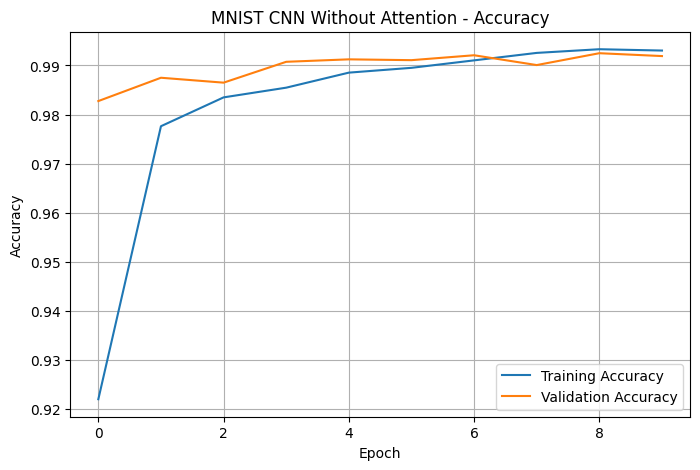

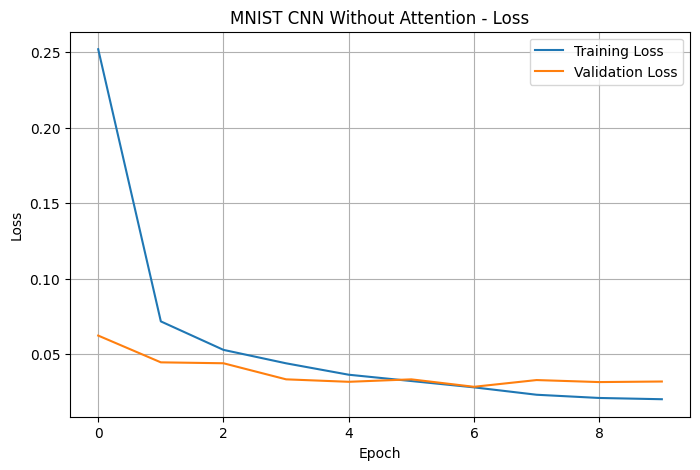

In [7]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_mnist_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_mnist_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("MNIST CNN Without Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_mnist_cnn.history["loss"], label="Training Loss")
plt.plot(history_mnist_cnn.history["val_loss"], label="Validation Loss")
plt.title("MNIST CNN Without Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
# =========================
# PART 7: EVALUATE OFFICIAL TEST SET
# =========================

official_test_loss_mnist_cnn, official_test_accuracy_mnist_cnn = model_mnist_cnn.evaluate(
    x_test_mnist,
    y_test_mnist,
    verbose=1
)

print("Official MNIST Test Loss:", official_test_loss_mnist_cnn)
print("Official MNIST Test Accuracy:", official_test_accuracy_mnist_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9927 - loss: 0.0209
Official MNIST Test Loss: 0.020938515663146973
Official MNIST Test Accuracy: 0.9926999807357788


In [9]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_mnist_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/MNIST"

external_images_mnist = []
external_labels_mnist = []

for label in range(10):
    folder_path = os.path.join(external_mnist_path, str(label))

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith(".png"):
            image_path = os.path.join(folder_path, filename)

            # Convert to grayscale and resize to MNIST format
            img = Image.open(image_path).convert("L").resize((28, 28))

            # MNIST expects white digit on black background.
            # Keep this if your images are black digits on white background.
            img = ImageOps.invert(img)

            img_array = np.array(img).astype("float32") / 255.0
            img_array = img_array.reshape(28, 28, 1)

            external_images_mnist.append(img_array)
            external_labels_mnist.append(label)

external_images_mnist = np.array(external_images_mnist)
external_labels_mnist = np.array(external_labels_mnist)

print("External MNIST Images Shape:", external_images_mnist.shape)
print("External MNIST Labels Shape:", external_labels_mnist.shape)
print("Total External Images Loaded:", len(external_images_mnist))

Mounted at /content/drive
External MNIST Images Shape: (60, 28, 28, 1)
External MNIST Labels Shape: (60,)
Total External Images Loaded: 60


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
External Testing Accuracy: 0.75
Average Confidence Score: 76.21%


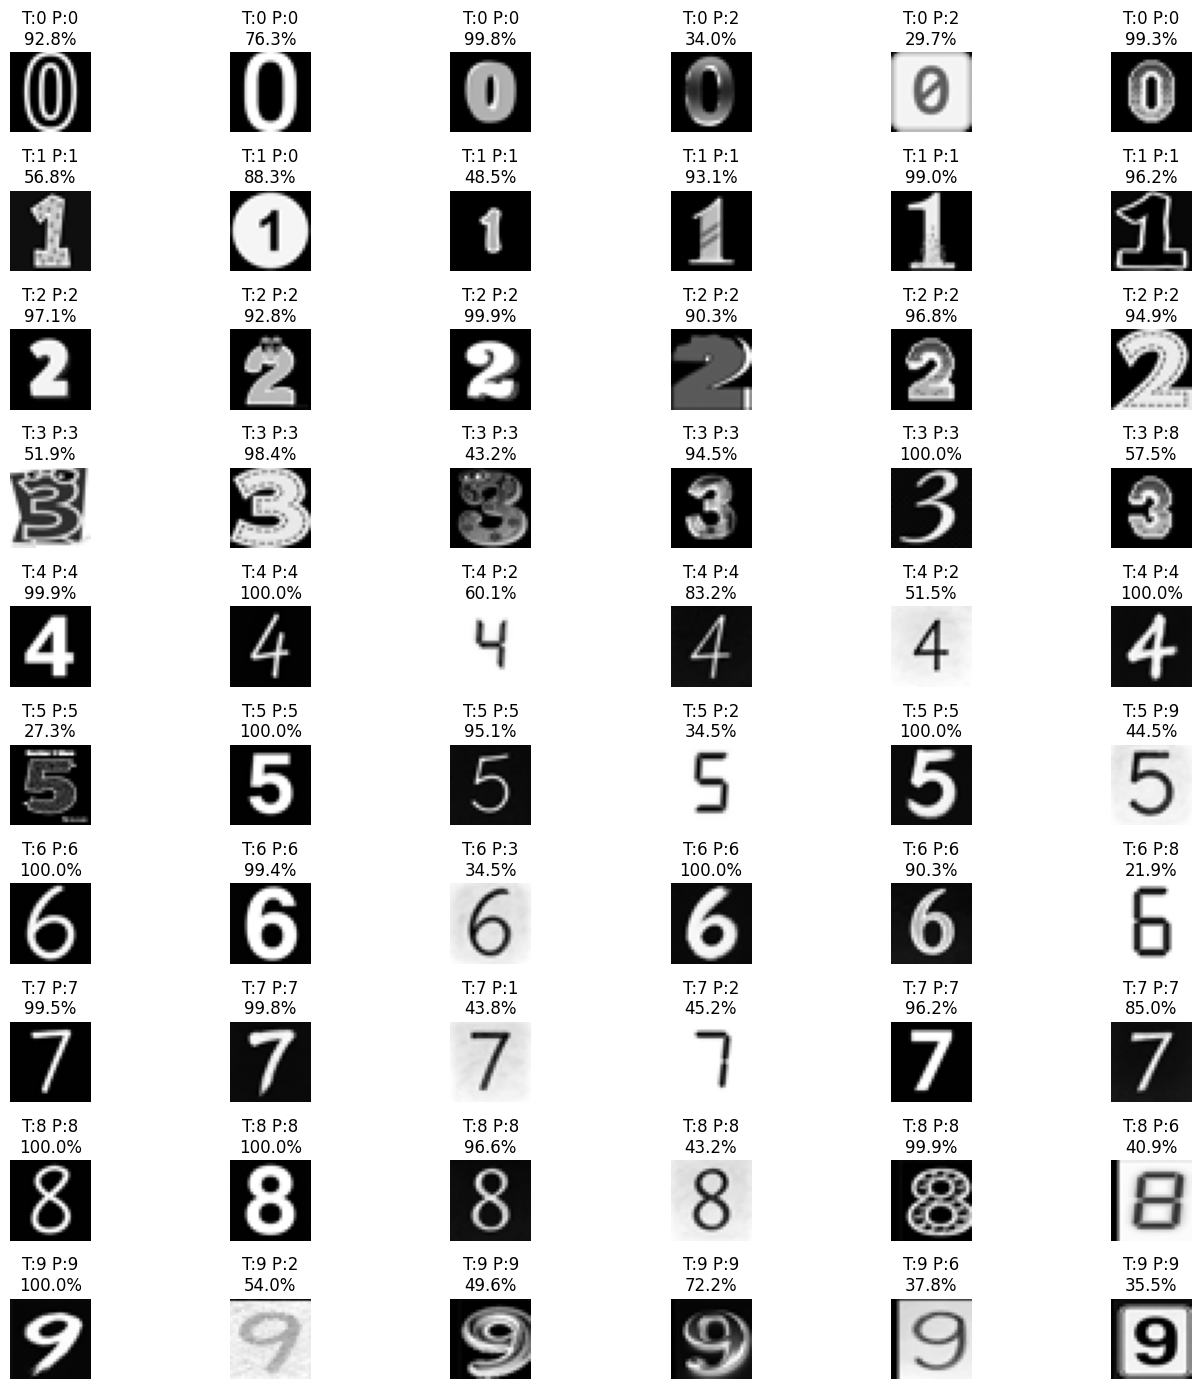

In [10]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_mnist_cnn = model_mnist_cnn.predict(external_images_mnist)

external_predicted_labels_mnist_cnn = np.argmax(
    external_predictions_mnist_cnn,
    axis=1
)

external_confidence_scores_mnist_cnn = np.max(
    external_predictions_mnist_cnn,
    axis=1
)

external_testing_accuracy_mnist_cnn = accuracy_score(
    external_labels_mnist,
    external_predicted_labels_mnist_cnn
)

average_confidence_mnist_cnn = np.mean(external_confidence_scores_mnist_cnn) * 100

print("External Testing Accuracy:", external_testing_accuracy_mnist_cnn)
print(f"Average Confidence Score: {average_confidence_mnist_cnn:.2f}%")

# Display external predictions
num_images = len(external_images_mnist)

plt.figure(figsize=(14, 14))

for i in range(num_images):
    plt.subplot(10, 6, i + 1)

    plt.imshow(external_images_mnist[i].reshape(28, 28), cmap="gray")

    true_label = class_names_mnist[external_labels_mnist[i]]
    predicted_label = class_names_mnist[external_predicted_labels_mnist_cnn[i]]
    confidence = external_confidence_scores_mnist_cnn[i] * 100

    plt.title(
        f"T:{true_label} P:{predicted_label}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

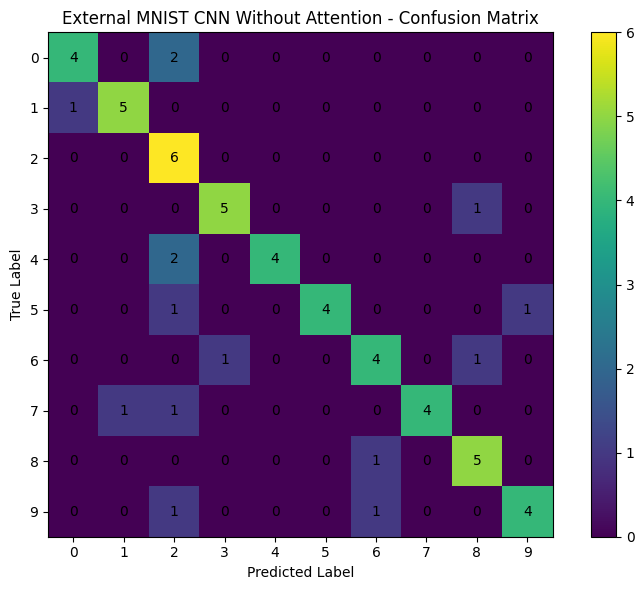


External MNIST CNN Without Attention - Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.67      0.73         6
           1       0.83      0.83      0.83         6
           2       0.46      1.00      0.63         6
           3       0.83      0.83      0.83         6
           4       1.00      0.67      0.80         6
           5       1.00      0.67      0.80         6
           6       0.67      0.67      0.67         6
           7       1.00      0.67      0.80         6
           8       0.71      0.83      0.77         6
           9       0.80      0.67      0.73         6

    accuracy                           0.75        60
   macro avg       0.81      0.75      0.76        60
weighted avg       0.81      0.75      0.76        60


Overall External Test Metrics:
Training Accuracy:          0.9930
Validation Accuracy:        0.9919
Official Test Accuracy:     0.9927
External Testing Accuracy:  0.7500
Precis

In [13]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# MODEL 1: MNIST CNN WITHOUT ATTENTION
# =========================

# Create confusion matrix first
external_conf_matrix_mnist_cnn = confusion_matrix(
    external_labels_mnist,
    external_predicted_labels_mnist_cnn
)

# Display confusion matrix
plt.figure(figsize=(8, 6))
plt.imshow(external_conf_matrix_mnist_cnn, interpolation="nearest")
plt.title("External MNIST CNN Without Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(class_names_mnist))
plt.xticks(tick_marks, class_names_mnist)
plt.yticks(tick_marks, class_names_mnist)

for i in range(external_conf_matrix_mnist_cnn.shape[0]):
    for j in range(external_conf_matrix_mnist_cnn.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_mnist_cnn[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal MNIST CNN Without Attention - Classification Report:")
print(
    classification_report(
        external_labels_mnist,
        external_predicted_labels_mnist_cnn,
        target_names=class_names_mnist,
        zero_division=0
    )
)

# Overall metrics
external_precision_mnist_cnn = precision_score(
    external_labels_mnist,
    external_predicted_labels_mnist_cnn,
    average="weighted",
    zero_division=0
)

external_recall_mnist_cnn = recall_score(
    external_labels_mnist,
    external_predicted_labels_mnist_cnn,
    average="weighted",
    zero_division=0
)

external_f1_mnist_cnn = f1_score(
    external_labels_mnist,
    external_predicted_labels_mnist_cnn,
    average="weighted",
    zero_division=0
)

print("\nOverall External Test Metrics:")
print(f"Training Accuracy:          {final_training_accuracy_mnist_cnn:.4f}")
print(f"Validation Accuracy:        {final_validation_accuracy_mnist_cnn:.4f}")
print(f"Official Test Accuracy:     {official_test_accuracy_mnist_cnn:.4f}")
print(f"External Testing Accuracy:  {external_testing_accuracy_mnist_cnn:.4f}")
print(f"Precision:                  {external_precision_mnist_cnn:.4f}")
print(f"Recall:                     {external_recall_mnist_cnn:.4f}")
print(f"F1-Score:                   {external_f1_mnist_cnn:.4f}")
print(f"Average Confidence:         {average_confidence_mnist_cnn:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_mnist_cnn_pickle_path = os.path.join(
    model_save_folder,
    "model_mnist_cnn_without_attention.pkl"
)

with open(model_mnist_cnn_pickle_path, "wb") as file:
    pickle.dump(model_mnist_cnn, file)

print("Model 1 saved successfully as pickle file.")
print("Saved path:", model_mnist_cnn_pickle_path)

**MNIST With Attention**  
The following model is a standard CNN model with attention for MNIST.

In [14]:
# =========================
# MODEL 2: MNIST CNN WITH ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_mnist_att, y_train_mnist_att), (x_test_mnist_att, y_test_mnist_att) = mnist.load_data()

print("MNIST Training Images Shape:", x_train_mnist_att.shape)
print("MNIST Training Labels Shape:", y_train_mnist_att.shape)
print("MNIST Official Test Images Shape:", x_test_mnist_att.shape)
print("MNIST Official Test Labels Shape:", y_test_mnist_att.shape)

MNIST Training Images Shape: (60000, 28, 28)
MNIST Training Labels Shape: (60000,)
MNIST Official Test Images Shape: (10000, 28, 28)
MNIST Official Test Labels Shape: (10000,)


In [15]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

# Reshape because CNN expects channel dimension: 28x28x1
x_train_mnist_att = x_train_mnist_att.reshape(-1, 28, 28, 1)
x_test_mnist_att = x_test_mnist_att.reshape(-1, 28, 28, 1)

# Normalize pixel values from 0-255 to 0-1
x_train_mnist_att = x_train_mnist_att.astype("float32") / 255.0
x_test_mnist_att = x_test_mnist_att.astype("float32") / 255.0

print("After preprocessing:")
print("MNIST Training Images Shape:", x_train_mnist_att.shape)
print("MNIST Official Test Images Shape:", x_test_mnist_att.shape)
print("Minimum Pixel Value:", x_train_mnist_att.min())
print("Maximum Pixel Value:", x_train_mnist_att.max())

After preprocessing:
MNIST Training Images Shape: (60000, 28, 28, 1)
MNIST Official Test Images Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [16]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_mnist = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9"
]

In [17]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# CNN WITH ATTENTION
# =========================

input_shape_mnist = (28, 28, 1)
num_classes_mnist = 10

inputs = tf.keras.Input(shape=input_shape_mnist)

# CNN feature extractor
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convert CNN feature map into sequence format for attention
x = layers.Reshape((-1, x.shape[-1]))(x)

query = x
key = x
value = x

# Attention layer
attention_layer = layers.Attention(use_scale=True)
attn_output = attention_layer([query, value, key])

# Combine original CNN features and attention output
x = layers.Concatenate()([x, attn_output])

# Classifier
x = layers.Flatten()(x)

# Dropout helps reduce overfitting
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes_mnist, activation="softmax")(x)

model_mnist_attention = models.Model(inputs=inputs, outputs=outputs)

model_mnist_attention.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mnist_attention.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 28, 28,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 14, 14,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 14, 14,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 7, 7, 64)  │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 7, 7, 64)  │     36,928 │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 3, 3, 64)  │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 9, 64)     │          0 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 9, 64)     │          1 │ reshape[0][0],    │
│ (Attention)         │                   │            │ reshape[0][0],    │
│                     │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 9, 128)    │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1152)      │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 1152)      │          0 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │     11,530 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 67,275 (262.79 KB)

 Trainable params: 67,275 (262.79 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING
# =========================

early_stopping_mnist_attention = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_mnist_attention = model_mnist_attention.fit(
    x_train_mnist_att,
    y_train_mnist_att,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_mnist_attention],
    verbose=1
)

# Get final training and validation accuracy
final_training_accuracy_mnist_attention = history_mnist_attention.history["accuracy"][-1]
final_validation_accuracy_mnist_attention = history_mnist_attention.history["val_accuracy"][-1]

print("Final Training Accuracy:", final_training_accuracy_mnist_attention)
print("Final Validation Accuracy:", final_validation_accuracy_mnist_attention)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 75s 98ms/step - accuracy: 0.9189 - loss: 0.2537 - val_accuracy: 0.9798 - val_loss: 0.0696
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 77s 103ms/step - accuracy: 0.9778 - loss: 0.0713 - val_accuracy: 0.9858 - val_loss: 0.0463
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 99ms/step - accuracy: 0.9830 - loss: 0.0539 - val_accuracy: 0.9876 - val_loss: 0.0401
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 96ms/step - accuracy: 0.9872 - loss: 0.0407 - val_accuracy: 0.9908 - val_loss: 0.0338
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 98ms/step - accuracy: 0.9894 - loss: 0.0334 - val_accuracy: 0.9913 - val_loss: 0.0296
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 73s 98ms/step - accuracy: 0.9908 - loss: 0.0280 - val_accuracy: 0.9924 - val_loss: 0.0289
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 95ms/step - accuracy: 0.9919 - loss: 0.0235 - val_accuracy: 0.9911 - val_loss: 0.0363
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 98ms/step - accuracy: 0.9928 - loss: 0.0223 -

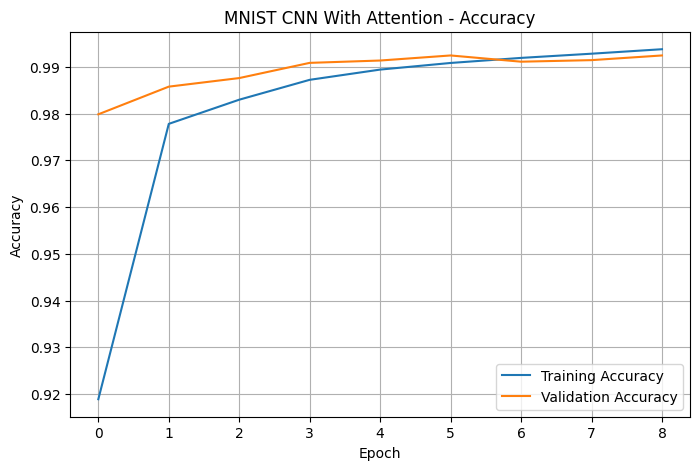

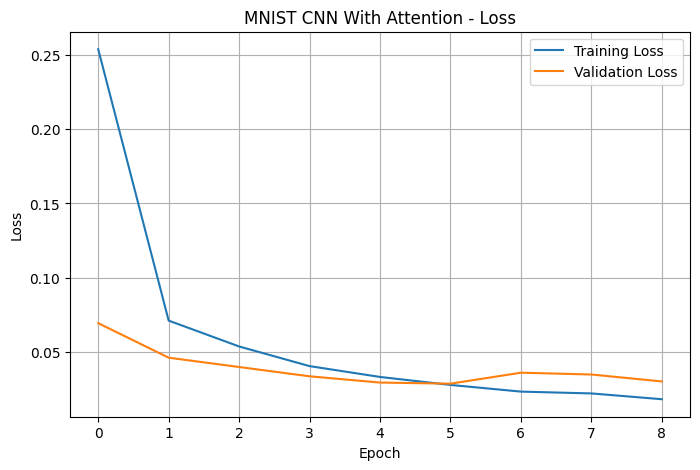

In [19]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_mnist_attention.history["accuracy"], label="Training Accuracy")
plt.plot(history_mnist_attention.history["val_accuracy"], label="Validation Accuracy")
plt.title("MNIST CNN With Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_mnist_attention.history["loss"], label="Training Loss")
plt.plot(history_mnist_attention.history["val_loss"], label="Validation Loss")
plt.title("MNIST CNN With Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# =========================
# PART 7: EVALUATE OFFICIAL TEST SET
# =========================

official_test_loss_mnist_attention, official_test_accuracy_mnist_attention = model_mnist_attention.evaluate(
    x_test_mnist_att,
    y_test_mnist_att,
    verbose=1
)

print("Official MNIST Test Loss:", official_test_loss_mnist_attention)
print("Official MNIST Test Accuracy:", official_test_accuracy_mnist_attention)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9913 - loss: 0.0253
Official MNIST Test Loss: 0.025266781449317932
Official MNIST Test Accuracy: 0.9912999868392944


In [21]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_mnist_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/MNIST"

external_images_mnist_attention = []
external_labels_mnist_attention = []

for label in range(10):
    folder_path = os.path.join(external_mnist_path, str(label))

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith(".png"):
            image_path = os.path.join(folder_path, filename)

            # Convert to grayscale and resize to MNIST format
            img = Image.open(image_path).convert("L").resize((28, 28))

            # MNIST expects white digit on black background.
            # Keep this if your images are black digits on white background.
            img = ImageOps.invert(img)

            img_array = np.array(img).astype("float32") / 255.0
            img_array = img_array.reshape(28, 28, 1)

            external_images_mnist_attention.append(img_array)
            external_labels_mnist_attention.append(label)

external_images_mnist_attention = np.array(external_images_mnist_attention)
external_labels_mnist_attention = np.array(external_labels_mnist_attention)

print("External MNIST Images Shape:", external_images_mnist_attention.shape)
print("External MNIST Labels Shape:", external_labels_mnist_attention.shape)
print("Total External Images Loaded:", len(external_images_mnist_attention))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
External MNIST Images Shape: (60, 28, 28, 1)
External MNIST Labels Shape: (60,)
Total External Images Loaded: 60


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
External Testing Accuracy: 0.6
Average Confidence Score: 76.26%


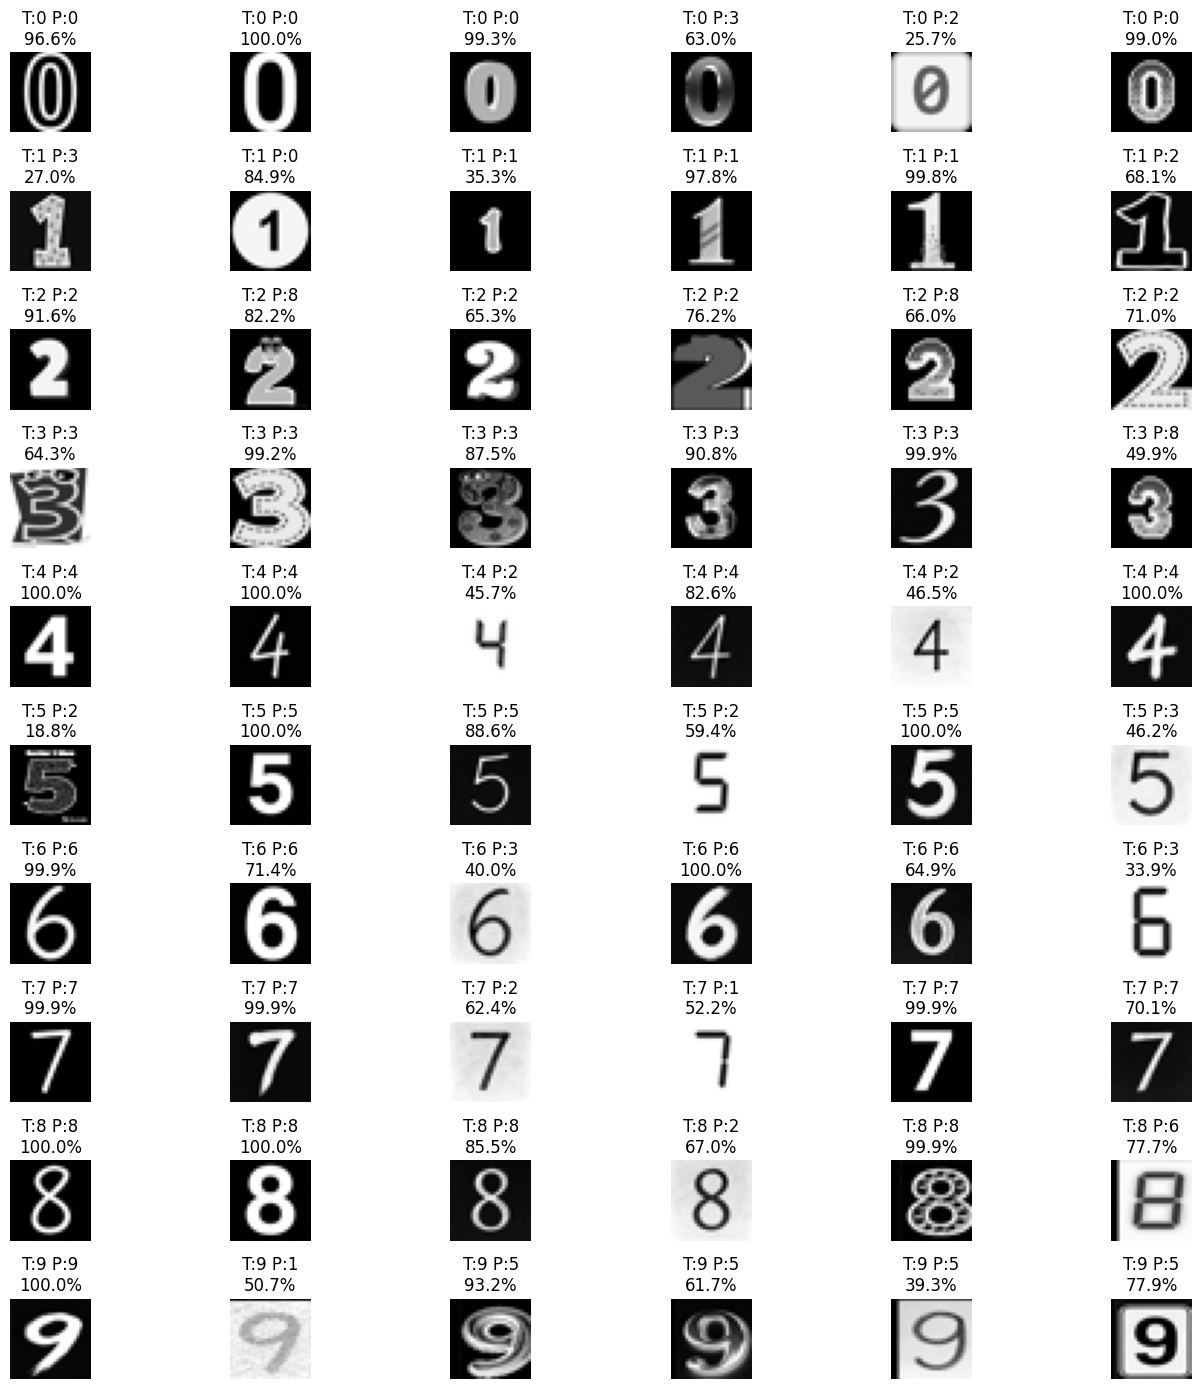

In [22]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_mnist_attention = model_mnist_attention.predict(
    external_images_mnist_attention
)

external_predicted_labels_mnist_attention = np.argmax(
    external_predictions_mnist_attention,
    axis=1
)

external_confidence_scores_mnist_attention = np.max(
    external_predictions_mnist_attention,
    axis=1
)

external_testing_accuracy_mnist_attention = accuracy_score(
    external_labels_mnist_attention,
    external_predicted_labels_mnist_attention
)

average_confidence_mnist_attention = np.mean(
    external_confidence_scores_mnist_attention
) * 100

print("External Testing Accuracy:", external_testing_accuracy_mnist_attention)
print(f"Average Confidence Score: {average_confidence_mnist_attention:.2f}%")

# Display external predictions
num_images = len(external_images_mnist_attention)

plt.figure(figsize=(14, 14))

for i in range(num_images):
    plt.subplot(10, 6, i + 1)

    plt.imshow(external_images_mnist_attention[i].reshape(28, 28), cmap="gray")

    true_label = class_names_mnist[external_labels_mnist_attention[i]]
    predicted_label = class_names_mnist[external_predicted_labels_mnist_attention[i]]
    confidence = external_confidence_scores_mnist_attention[i] * 100

    plt.title(
        f"T:{true_label} P:{predicted_label}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

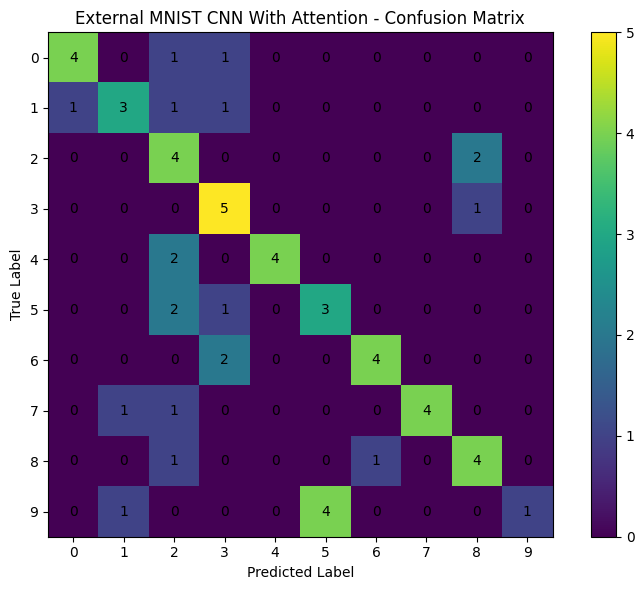


External MNIST CNN With Attention - Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.67      0.73         6
           1       0.60      0.50      0.55         6
           2       0.33      0.67      0.44         6
           3       0.50      0.83      0.62         6
           4       1.00      0.67      0.80         6
           5       0.43      0.50      0.46         6
           6       0.80      0.67      0.73         6
           7       1.00      0.67      0.80         6
           8       0.57      0.67      0.62         6
           9       1.00      0.17      0.29         6

    accuracy                           0.60        60
   macro avg       0.70      0.60      0.60        60
weighted avg       0.70      0.60      0.60        60


Overall External Test Metrics:
Training Accuracy:        0.9937
Validation Accuracy:      0.9924
Official Test Accuracy:   0.9913
External Testing Accuracy:0.6000
Precision:       

In [23]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# =========================

# Confusion matrix
external_conf_matrix_mnist_attention = confusion_matrix(
    external_labels_mnist_attention,
    external_predicted_labels_mnist_attention
)

plt.figure(figsize=(8, 6))
plt.imshow(external_conf_matrix_mnist_attention, interpolation="nearest")
plt.title("External MNIST CNN With Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(class_names_mnist))
plt.xticks(tick_marks, class_names_mnist)
plt.yticks(tick_marks, class_names_mnist)

for i in range(external_conf_matrix_mnist_attention.shape[0]):
    for j in range(external_conf_matrix_mnist_attention.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_mnist_attention[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal MNIST CNN With Attention - Classification Report:")
print(
    classification_report(
        external_labels_mnist_attention,
        external_predicted_labels_mnist_attention,
        target_names=class_names_mnist,
        zero_division=0
    )
)

# Overall metrics
external_precision_mnist_attention = precision_score(
    external_labels_mnist_attention,
    external_predicted_labels_mnist_attention,
    average="weighted",
    zero_division=0
)

external_recall_mnist_attention = recall_score(
    external_labels_mnist_attention,
    external_predicted_labels_mnist_attention,
    average="weighted",
    zero_division=0
)

external_f1_mnist_attention = f1_score(
    external_labels_mnist_attention,
    external_predicted_labels_mnist_attention,
    average="weighted",
    zero_division=0
)

print("\nOverall External Test Metrics:")
print(f"Training Accuracy:        {final_training_accuracy_mnist_attention:.4f}")
print(f"Validation Accuracy:      {final_validation_accuracy_mnist_attention:.4f}")
print(f"Official Test Accuracy:   {official_test_accuracy_mnist_attention:.4f}")
print(f"External Testing Accuracy:{external_testing_accuracy_mnist_attention:.4f}")
print(f"Precision:                {external_precision_mnist_attention:.4f}")
print(f"Recall:                   {external_recall_mnist_attention:.4f}")
print(f"F1-Score:                 {external_f1_mnist_attention:.4f}")
print(f"Average Confidence:       {average_confidence_mnist_attention:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_mnist_attention_pickle_path = os.path.join(
    model_save_folder,
    "model_mnist_cnn_with_attention.pkl"
)

with open(model_mnist_attention_pickle_path, "wb") as file:
    pickle.dump(model_mnist_attention, file)

print("Model 2 saved successfully as pickle file.")
print("Saved path:", model_mnist_attention_pickle_path)

**Cifar10 Without Attention**  
The following model is a standard CNN for Cifar10.

In [26]:
# =========================
# MODEL 3: CIFAR-10 CNN WITHOUT ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_cifar10, y_train_cifar10), (x_test_cifar10, y_test_cifar10) = cifar10.load_data()

print("CIFAR-10 Training Images Shape:", x_train_cifar10.shape)
print("CIFAR-10 Training Labels Shape:", y_train_cifar10.shape)
print("CIFAR-10 Official Test Images Shape:", x_test_cifar10.shape)
print("CIFAR-10 Official Test Labels Shape:", y_test_cifar10.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 36s 0us/step
CIFAR-10 Training Images Shape: (50000, 32, 32, 3)
CIFAR-10 Training Labels Shape: (50000, 1)
CIFAR-10 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-10 Official Test Labels Shape: (10000, 1)


In [27]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

# Normalize pixel values from 0-255 to 0-1
x_train_cifar10 = x_train_cifar10.astype("float32") / 255.0
x_test_cifar10 = x_test_cifar10.astype("float32") / 255.0

# Flatten labels from (50000, 1) to (50000,)
y_train_cifar10 = y_train_cifar10.flatten()
y_test_cifar10 = y_test_cifar10.flatten()

print("After preprocessing:")
print("CIFAR-10 Training Images Shape:", x_train_cifar10.shape)
print("CIFAR-10 Training Labels Shape:", y_train_cifar10.shape)
print("CIFAR-10 Official Test Images Shape:", x_test_cifar10.shape)
print("CIFAR-10 Official Test Labels Shape:", y_test_cifar10.shape)
print("Minimum Pixel Value:", x_train_cifar10.min())
print("Maximum Pixel Value:", x_train_cifar10.max())

After preprocessing:
CIFAR-10 Training Images Shape: (50000, 32, 32, 3)
CIFAR-10 Training Labels Shape: (50000,)
CIFAR-10 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-10 Official Test Labels Shape: (10000,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [28]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_cifar10 = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

In [29]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# CNN WITHOUT ATTENTION
# =========================

input_shape_cifar10 = (32, 32, 3)
num_classes_cifar10 = 10

inputs = tf.keras.Input(shape=input_shape_cifar10)

x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)

# Dropout helps reduce overfitting
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes_cifar10, activation="softmax")(x)

model_cifar10_cnn = models.Model(inputs=inputs, outputs=outputs)

model_cifar10_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cifar10_cnn.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,570 (260.04 KB)

 Trainable params: 66,570 (260.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING
# =========================

early_stopping_cifar10_cnn = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cifar10_cnn = model_cifar10_cnn.fit(
    x_train_cifar10,
    y_train_cifar10,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_cifar10_cnn],
    verbose=1
)

# Get final training and validation accuracy
final_training_accuracy_cifar10_cnn = history_cifar10_cnn.history["accuracy"][-1]
final_validation_accuracy_cifar10_cnn = history_cifar10_cnn.history["val_accuracy"][-1]

print("Final Training Accuracy:", final_training_accuracy_cifar10_cnn)
print("Final Validation Accuracy:", final_validation_accuracy_cifar10_cnn)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 133ms/step - accuracy: 0.3955 - loss: 1.6589 - val_accuracy: 0.5297 - val_loss: 1.3342
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 134ms/step - accuracy: 0.5442 - loss: 1.2791 - val_accuracy: 0.6043 - val_loss: 1.1341
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 146s 140ms/step - accuracy: 0.6074 - loss: 1.1118 - val_accuracy: 0.6464 - val_loss: 1.0138
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 140ms/step - accuracy: 0.6461 - loss: 1.0135 - val_accuracy: 0.6767 - val_loss: 0.9507
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.6716 - loss: 0.9454 - val_accuracy: 0.6948 - val_loss: 0.8937
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 147s 139ms/step - accuracy: 0.6911 - loss: 0.8893 - val_accuracy: 0.6993 - val_loss: 0.8770
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.7051 - loss: 0.8428 - val_accuracy: 0.7177 - val_loss: 0.8268
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 134ms/step - accuracy: 0.7153 - los

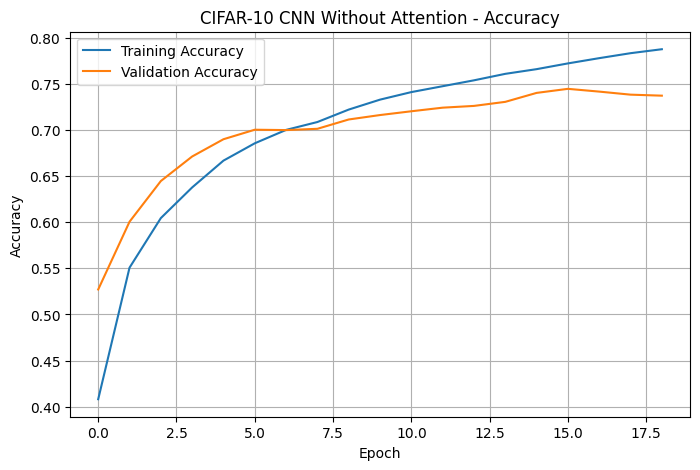

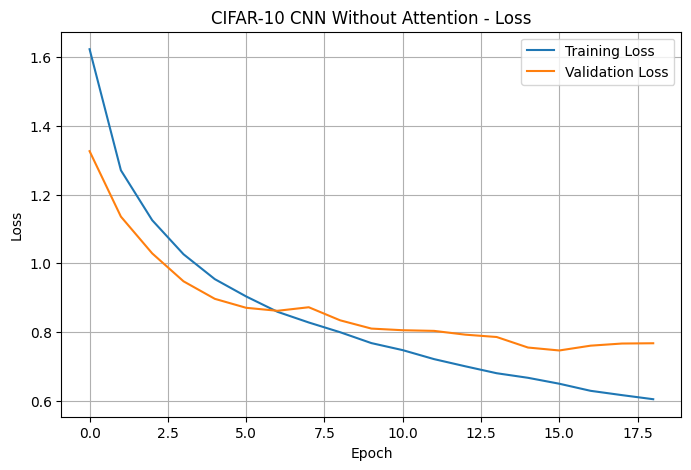

In [ ]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_cifar10_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cifar10_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CIFAR-10 CNN Without Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_cifar10_cnn.history["loss"], label="Training Loss")
plt.plot(history_cifar10_cnn.history["val_loss"], label="Validation Loss")
plt.title("CIFAR-10 CNN Without Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# =========================
# PART 7: EVALUATE OFFICIAL TEST SET
# =========================

official_test_loss_cifar10_cnn, official_test_accuracy_cifar10_cnn = model_cifar10_cnn.evaluate(
    x_test_cifar10,
    y_test_cifar10,
    verbose=1
)

print("Official CIFAR-10 Test Loss:", official_test_loss_cifar10_cnn)
print("Official CIFAR-10 Test Accuracy:", official_test_accuracy_cifar10_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7419 - loss: 0.7614
Official CIFAR-10 Test Loss: 0.7613990306854248
Official CIFAR-10 Test Accuracy: 0.7419000267982483


In [ ]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_cifar10_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/Cifar10"

cifar10_folder_label_map = {
    "Airplane": 0,
    "Automobile": 1,
    "Bird": 2,
    "Cat": 3,
    "Deer": 4,
    "Dog": 5,
    "Frog": 6,
    "Horse": 7,
    "Ship": 8,
    "Truck": 9
}

external_images_cifar10 = []
external_labels_cifar10 = []

for folder_name, label in cifar10_folder_label_map.items():
    folder_path = os.path.join(external_cifar10_path, folder_name)

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            image_path = os.path.join(folder_path, filename)

            # CIFAR-10 expects RGB images resized to 32x32
            img = Image.open(image_path).convert("RGB").resize((32, 32))

            img_array = np.array(img).astype("float32") / 255.0

            external_images_cifar10.append(img_array)
            external_labels_cifar10.append(label)

external_images_cifar10 = np.array(external_images_cifar10)
external_labels_cifar10 = np.array(external_labels_cifar10)

print("External CIFAR-10 Images Shape:", external_images_cifar10.shape)
print("External CIFAR-10 Labels Shape:", external_labels_cifar10.shape)
print("Total External Images Loaded:", len(external_images_cifar10))

Mounted at /content/drive
External CIFAR-10 Images Shape: (60, 32, 32, 3)
External CIFAR-10 Labels Shape: (60,)
Total External Images Loaded: 60


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
External Testing Accuracy: 0.7333333333333333
Average Confidence Score: 80.81%


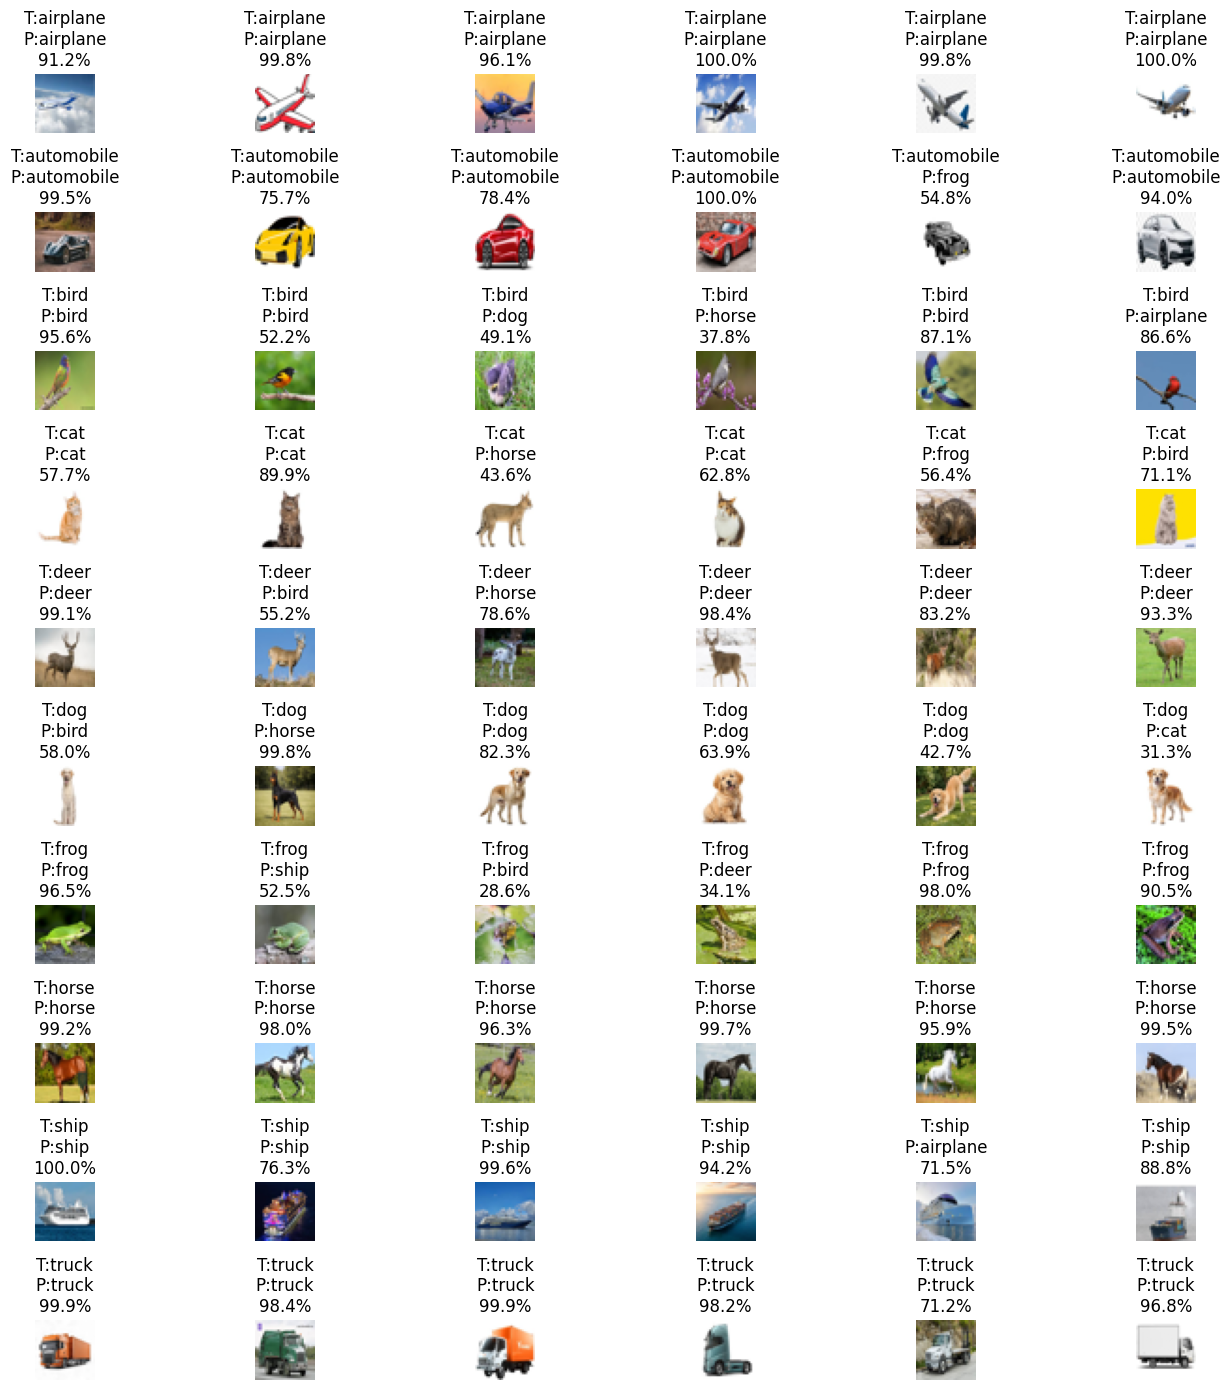

In [ ]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_cifar10_cnn = model_cifar10_cnn.predict(external_images_cifar10)

external_predicted_labels_cifar10_cnn = np.argmax(
    external_predictions_cifar10_cnn,
    axis=1
)

external_confidence_scores_cifar10_cnn = np.max(
    external_predictions_cifar10_cnn,
    axis=1
)

external_testing_accuracy_cifar10_cnn = accuracy_score(
    external_labels_cifar10,
    external_predicted_labels_cifar10_cnn
)

average_confidence_cifar10_cnn = np.mean(external_confidence_scores_cifar10_cnn) * 100

print("External Testing Accuracy:", external_testing_accuracy_cifar10_cnn)
print(f"Average Confidence Score: {average_confidence_cifar10_cnn:.2f}%")

# Display external predictions
num_images = len(external_images_cifar10)

plt.figure(figsize=(14, 14))

for i in range(num_images):
    plt.subplot(10, 6, i + 1)

    plt.imshow(external_images_cifar10[i])

    true_label = class_names_cifar10[external_labels_cifar10[i]]
    predicted_label = class_names_cifar10[external_predicted_labels_cifar10_cnn[i]]
    confidence = external_confidence_scores_cifar10_cnn[i] * 100

    plt.title(
        f"T:{true_label}\nP:{predicted_label}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

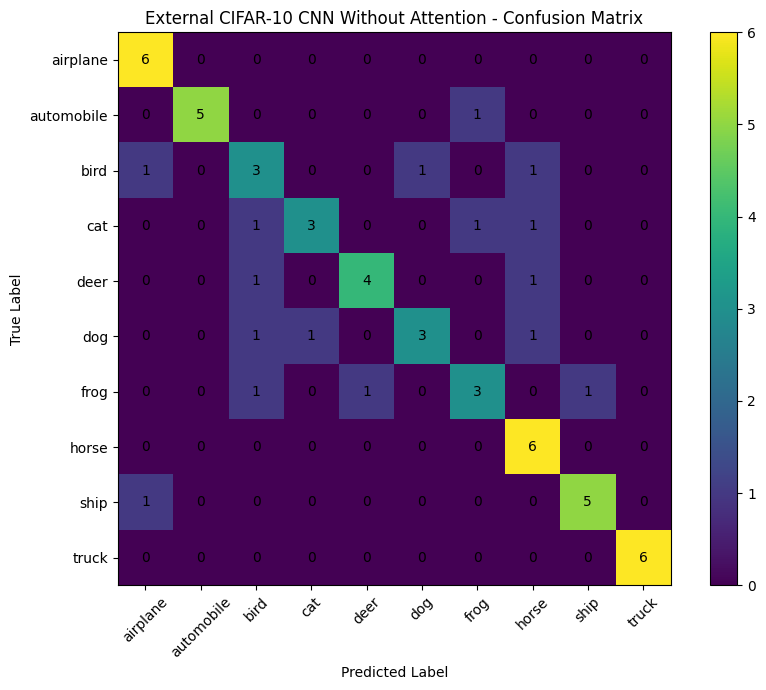


External CIFAR-10 CNN Without Attention - Classification Report:
              precision    recall  f1-score   support

    airplane       0.75      1.00      0.86         6
  automobile       1.00      0.83      0.91         6
        bird       0.43      0.50      0.46         6
         cat       0.75      0.50      0.60         6
        deer       0.80      0.67      0.73         6
         dog       0.75      0.50      0.60         6
        frog       0.60      0.50      0.55         6
       horse       0.60      1.00      0.75         6
        ship       0.83      0.83      0.83         6
       truck       1.00      1.00      1.00         6

    accuracy                           0.73        60
   macro avg       0.75      0.73      0.73        60
weighted avg       0.75      0.73      0.73        60


Overall External Test Metrics:
Training Accuracy:         0.7874
Validation Accuracy:       0.7371
Official Test Accuracy:    0.7419
External Testing Accuracy: 0.7333
Precisi

In [ ]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# =========================

external_conf_matrix_cifar10_cnn = confusion_matrix(
    external_labels_cifar10,
    external_predicted_labels_cifar10_cnn
)

plt.figure(figsize=(9, 7))
plt.imshow(external_conf_matrix_cifar10_cnn, interpolation="nearest")
plt.title("External CIFAR-10 CNN Without Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(class_names_cifar10))
plt.xticks(tick_marks, class_names_cifar10, rotation=45)
plt.yticks(tick_marks, class_names_cifar10)

for i in range(external_conf_matrix_cifar10_cnn.shape[0]):
    for j in range(external_conf_matrix_cifar10_cnn.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_cifar10_cnn[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal CIFAR-10 CNN Without Attention - Classification Report:")
print(
    classification_report(
        external_labels_cifar10,
        external_predicted_labels_cifar10_cnn,
        target_names=class_names_cifar10,
        zero_division=0
    )
)

external_precision_cifar10_cnn = precision_score(
    external_labels_cifar10,
    external_predicted_labels_cifar10_cnn,
    average="weighted",
    zero_division=0
)

external_recall_cifar10_cnn = recall_score(
    external_labels_cifar10,
    external_predicted_labels_cifar10_cnn,
    average="weighted",
    zero_division=0
)

external_f1_cifar10_cnn = f1_score(
    external_labels_cifar10,
    external_predicted_labels_cifar10_cnn,
    average="weighted",
    zero_division=0
)

print("\nOverall External Test Metrics:")
print(f"Training Accuracy:         {final_training_accuracy_cifar10_cnn:.4f}")
print(f"Validation Accuracy:       {final_validation_accuracy_cifar10_cnn:.4f}")
print(f"Official Test Accuracy:    {official_test_accuracy_cifar10_cnn:.4f}")
print(f"External Testing Accuracy: {external_testing_accuracy_cifar10_cnn:.4f}")
print(f"Precision:                 {external_precision_cifar10_cnn:.4f}")
print(f"Recall:                    {external_recall_cifar10_cnn:.4f}")
print(f"F1-Score:                  {external_f1_cifar10_cnn:.4f}")
print(f"Average Confidence:        {average_confidence_cifar10_cnn:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_cifar10_cnn_pickle_path = os.path.join(
    model_save_folder,
    "model_cifar10_cnn_without_attention.pkl"
)

with open(model_cifar10_cnn_pickle_path, "wb") as file:
    pickle.dump(model_cifar10_cnn, file)

print("Model 3 saved successfully as pickle file.")
print("Saved path:", model_cifar10_cnn_pickle_path)

**Cifar10 With Attention**  
The following model is a standard CNN with attention.

In [ ]:
# =========================
# MODEL 4: CIFAR-10 CNN WITH ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_cifar10_att, y_train_cifar10_att), (x_test_cifar10_att, y_test_cifar10_att) = cifar10.load_data()

print("CIFAR-10 Training Images Shape:", x_train_cifar10_att.shape)
print("CIFAR-10 Training Labels Shape:", y_train_cifar10_att.shape)
print("CIFAR-10 Official Test Images Shape:", x_test_cifar10_att.shape)
print("CIFAR-10 Official Test Labels Shape:", y_test_cifar10_att.shape)

CIFAR-10 Training Images Shape: (50000, 32, 32, 3)
CIFAR-10 Training Labels Shape: (50000, 1)
CIFAR-10 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-10 Official Test Labels Shape: (10000, 1)


In [ ]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

# Normalize pixel values from 0-255 to 0-1
x_train_cifar10_att = x_train_cifar10_att.astype("float32") / 255.0
x_test_cifar10_att = x_test_cifar10_att.astype("float32") / 255.0

# Flatten labels from (50000, 1) to (50000,)
y_train_cifar10_att = y_train_cifar10_att.flatten()
y_test_cifar10_att = y_test_cifar10_att.flatten()

print("After preprocessing:")
print("CIFAR-10 Training Images Shape:", x_train_cifar10_att.shape)
print("CIFAR-10 Training Labels Shape:", y_train_cifar10_att.shape)
print("CIFAR-10 Official Test Images Shape:", x_test_cifar10_att.shape)
print("CIFAR-10 Official Test Labels Shape:", y_test_cifar10_att.shape)
print("Minimum Pixel Value:", x_train_cifar10_att.min())
print("Maximum Pixel Value:", x_train_cifar10_att.max())

After preprocessing:
CIFAR-10 Training Images Shape: (50000, 32, 32, 3)
CIFAR-10 Training Labels Shape: (50000,)
CIFAR-10 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-10 Official Test Labels Shape: (10000,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [ ]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_cifar10 = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

In [ ]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# CNN WITH ATTENTION
# =========================

input_shape_cifar10 = (32, 32, 3)
num_classes_cifar10 = 10

inputs = tf.keras.Input(shape=input_shape_cifar10)

# CNN feature extractor
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convert CNN feature map to sequence format for attention
x = layers.Reshape((-1, x.shape[-1]))(x)

query = x
key = x
value = x

# Attention layer
attention_layer = layers.Attention(use_scale=True)
attn_output = attention_layer([query, value, key])

# Combine original CNN features and attention output
x = layers.Concatenate()([x, attn_output])

# Classifier
x = layers.Flatten()(x)

# Dropout helps reduce overfitting
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes_cifar10, activation="softmax")(x)

model_cifar10_attention = models.Model(inputs=inputs, outputs=outputs)

model_cifar10_attention.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cifar10_attention.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 8, 8, 64)  │          0 │ conv2d_4[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 8, 8, 64)  │     36,928 │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 4, 4, 64)  │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 16, 64)    │          0 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 16, 64)    │          1 │ reshape[0][0],    │
│ (Attention)         │                   │            │ reshape[0][0],    │
│                     │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 128)   │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 2048)      │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 2048)      │          0 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │     20,490 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 76,811 (300.04 KB)

 Trainable params: 76,811 (300.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING
# =========================

early_stopping_cifar10_attention = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cifar10_attention = model_cifar10_attention.fit(
    x_train_cifar10_att,
    y_train_cifar10_att,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_cifar10_attention],
    verbose=1
)

# Get final training and validation accuracy
final_training_accuracy_cifar10_attention = history_cifar10_attention.history["accuracy"][-1]
final_validation_accuracy_cifar10_attention = history_cifar10_attention.history["val_accuracy"][-1]

print("Final Training Accuracy:", final_training_accuracy_cifar10_attention)
print("Final Validation Accuracy:", final_validation_accuracy_cifar10_attention)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.4055 - loss: 1.6265 - val_accuracy: 0.5325 - val_loss: 1.3217
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5523 - loss: 1.2656 - val_accuracy: 0.5982 - val_loss: 1.1448
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6120 - loss: 1.1028 - val_accuracy: 0.6414 - val_loss: 1.0241
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6515 - loss: 0.9950 - val_accuracy: 0.6781 - val_loss: 0.9347
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6783 - loss: 0.9151 - val_accuracy: 0.6986 - val_loss: 0.8847
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7013 - loss: 0.8507 - val_accuracy: 0.7030 - val_loss: 0.8604
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7176 - loss: 0.8075 - val_accuracy: 0.7247 - val_loss: 0.8075
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7370 - loss: 0.7586 - val_accuracy: 0.

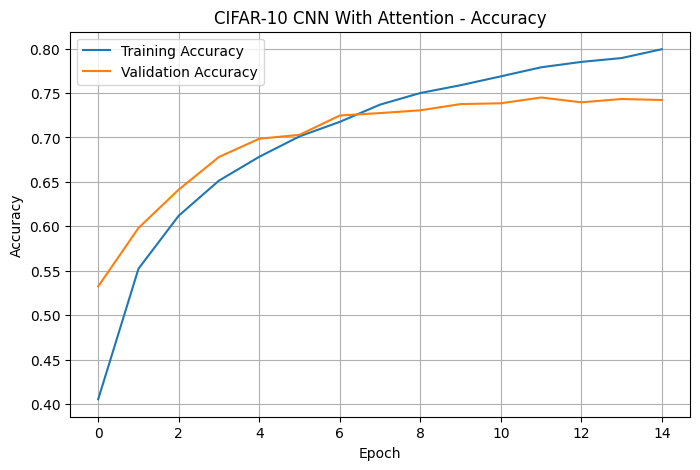

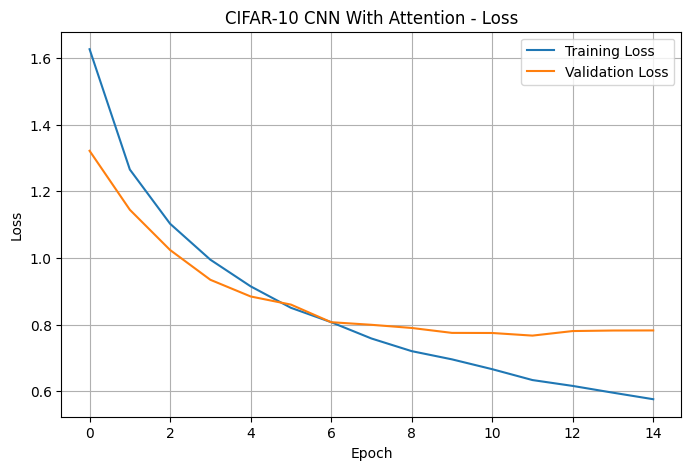

In [ ]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_cifar10_attention.history["accuracy"], label="Training Accuracy")
plt.plot(history_cifar10_attention.history["val_accuracy"], label="Validation Accuracy")
plt.title("CIFAR-10 CNN With Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_cifar10_attention.history["loss"], label="Training Loss")
plt.plot(history_cifar10_attention.history["val_loss"], label="Validation Loss")
plt.title("CIFAR-10 CNN With Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# =========================
# PART 7: EVALUATE OFFICIAL TEST SET
# =========================

official_test_loss_cifar10_attention, official_test_accuracy_cifar10_attention = model_cifar10_attention.evaluate(
    x_test_cifar10_att,
    y_test_cifar10_att,
    verbose=1
)

print("Official CIFAR-10 Test Loss:", official_test_loss_cifar10_attention)
print("Official CIFAR-10 Test Accuracy:", official_test_accuracy_cifar10_attention)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7342 - loss: 0.7912
Official CIFAR-10 Test Loss: 0.7911729216575623
Official CIFAR-10 Test Accuracy: 0.7342000007629395


In [ ]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_cifar10_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/Cifar10"

cifar10_folder_label_map = {
    "Airplane": 0,
    "Automobile": 1,
    "Bird": 2,
    "Cat": 3,
    "Deer": 4,
    "Dog": 5,
    "Frog": 6,
    "Horse": 7,
    "Ship": 8,
    "Truck": 9
}

external_images_cifar10_attention = []
external_labels_cifar10_attention = []

for folder_name, label in cifar10_folder_label_map.items():
    folder_path = os.path.join(external_cifar10_path, folder_name)

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            image_path = os.path.join(folder_path, filename)

            # CIFAR-10 expects RGB images resized to 32x32
            img = Image.open(image_path).convert("RGB").resize((32, 32))

            img_array = np.array(img).astype("float32") / 255.0

            external_images_cifar10_attention.append(img_array)
            external_labels_cifar10_attention.append(label)

external_images_cifar10_attention = np.array(external_images_cifar10_attention)
external_labels_cifar10_attention = np.array(external_labels_cifar10_attention)

print("External CIFAR-10 Images Shape:", external_images_cifar10_attention.shape)
print("External CIFAR-10 Labels Shape:", external_labels_cifar10_attention.shape)
print("Total External Images Loaded:", len(external_images_cifar10_attention))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
External CIFAR-10 Images Shape: (60, 32, 32, 3)
External CIFAR-10 Labels Shape: (60,)
Total External Images Loaded: 60


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 930ms/step
External Testing Accuracy: 0.7333333333333333
Average Confidence Score: 84.35%


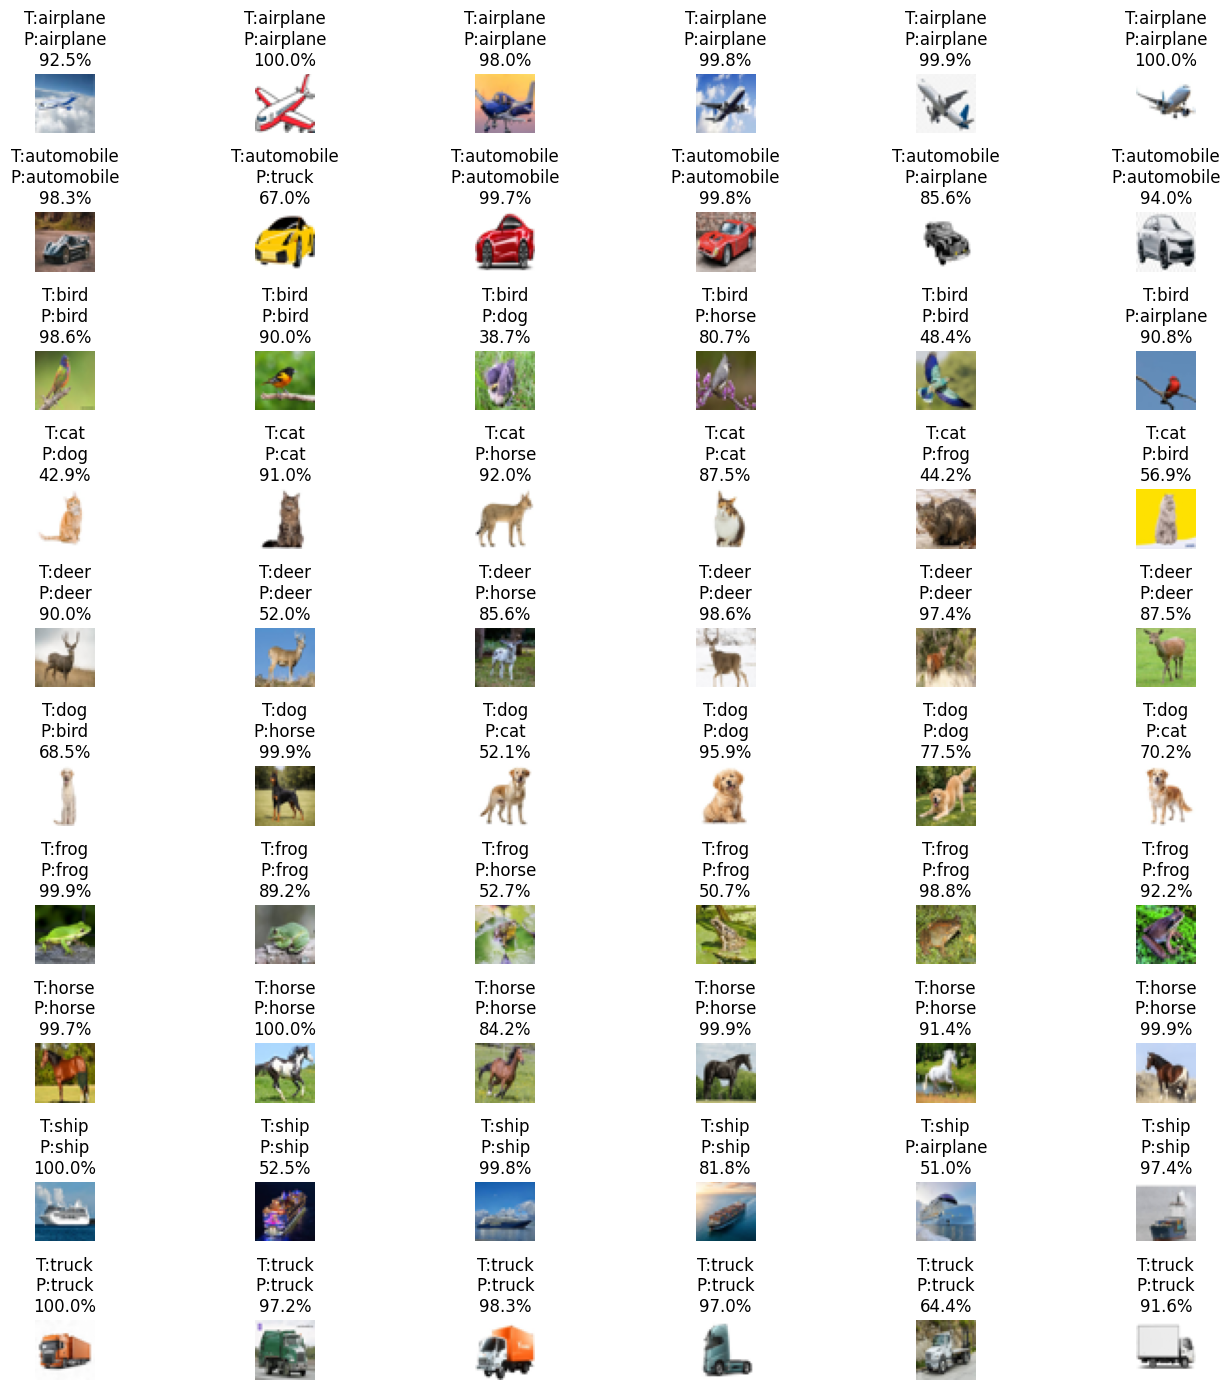

In [ ]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_cifar10_attention = model_cifar10_attention.predict(
    external_images_cifar10_attention
)

external_predicted_labels_cifar10_attention = np.argmax(
    external_predictions_cifar10_attention,
    axis=1
)

external_confidence_scores_cifar10_attention = np.max(
    external_predictions_cifar10_attention,
    axis=1
)

external_testing_accuracy_cifar10_attention = accuracy_score(
    external_labels_cifar10_attention,
    external_predicted_labels_cifar10_attention
)

average_confidence_cifar10_attention = np.mean(
    external_confidence_scores_cifar10_attention
) * 100

print("External Testing Accuracy:", external_testing_accuracy_cifar10_attention)
print(f"Average Confidence Score: {average_confidence_cifar10_attention:.2f}%")

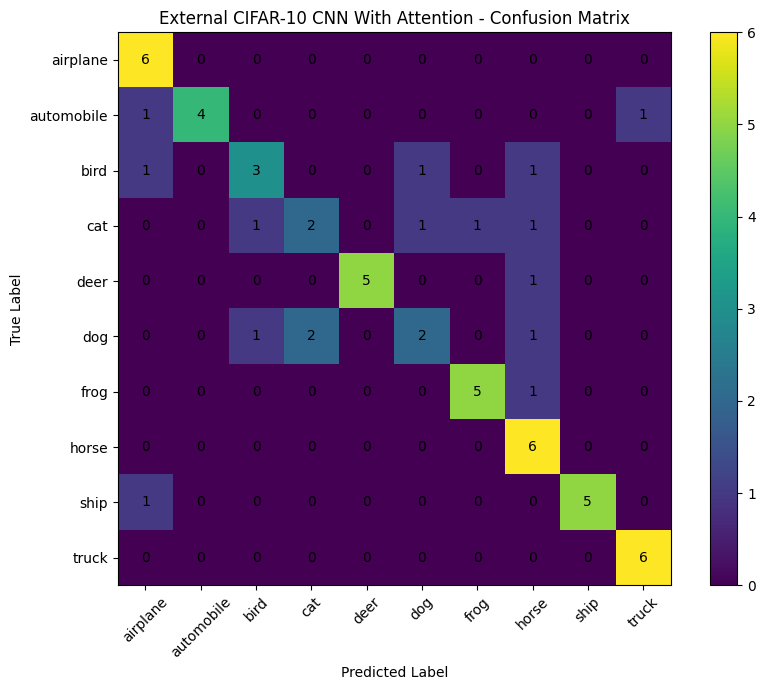


External CIFAR-10 CNN With Attention - Classification Report:
              precision    recall  f1-score   support

    airplane       0.67      1.00      0.80         6
  automobile       1.00      0.67      0.80         6
        bird       0.60      0.50      0.55         6
         cat       0.50      0.33      0.40         6
        deer       1.00      0.83      0.91         6
         dog       0.50      0.33      0.40         6
        frog       0.83      0.83      0.83         6
       horse       0.55      1.00      0.71         6
        ship       1.00      0.83      0.91         6
       truck       0.86      1.00      0.92         6

    accuracy                           0.73        60
   macro avg       0.75      0.73      0.72        60
weighted avg       0.75      0.73      0.72        60


Overall External Test Metrics:
Training Accuracy:         0.7993
Validation Accuracy:       0.7422
Official Test Accuracy:    0.7342
External Testing Accuracy: 0.7333
Precision:

In [ ]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# =========================

external_conf_matrix_cifar10_attention = confusion_matrix(
    external_labels_cifar10_attention,
    external_predicted_labels_cifar10_attention
)

plt.figure(figsize=(9, 7))
plt.imshow(external_conf_matrix_cifar10_attention, interpolation="nearest")
plt.title("External CIFAR-10 CNN With Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(class_names_cifar10))
plt.xticks(tick_marks, class_names_cifar10, rotation=45)
plt.yticks(tick_marks, class_names_cifar10)

for i in range(external_conf_matrix_cifar10_attention.shape[0]):
    for j in range(external_conf_matrix_cifar10_attention.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_cifar10_attention[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal CIFAR-10 CNN With Attention - Classification Report:")
print(
    classification_report(
        external_labels_cifar10_attention,
        external_predicted_labels_cifar10_attention,
        target_names=class_names_cifar10,
        zero_division=0
    )
)

external_precision_cifar10_attention = precision_score(
    external_labels_cifar10_attention,
    external_predicted_labels_cifar10_attention,
    average="weighted",
    zero_division=0
)

external_recall_cifar10_attention = recall_score(
    external_labels_cifar10_attention,
    external_predicted_labels_cifar10_attention,
    average="weighted",
    zero_division=0
)

external_f1_cifar10_attention = f1_score(
    external_labels_cifar10_attention,
    external_predicted_labels_cifar10_attention,
    average="weighted",
    zero_division=0
)

print("\nOverall External Test Metrics:")
print(f"Training Accuracy:         {final_training_accuracy_cifar10_attention:.4f}")
print(f"Validation Accuracy:       {final_validation_accuracy_cifar10_attention:.4f}")
print(f"Official Test Accuracy:    {official_test_accuracy_cifar10_attention:.4f}")
print(f"External Testing Accuracy: {external_testing_accuracy_cifar10_attention:.4f}")
print(f"Precision:                 {external_precision_cifar10_attention:.4f}")
print(f"Recall:                    {external_recall_cifar10_attention:.4f}")
print(f"F1-Score:                  {external_f1_cifar10_attention:.4f}")
print(f"Average Confidence:        {average_confidence_cifar10_attention:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_cifar10_attention_pickle_path = os.path.join(
    model_save_folder,
    "model_cifar10_cnn_with_attention.pkl"
)

with open(model_cifar10_attention_pickle_path, "wb") as file:
    pickle.dump(model_cifar10_attention, file)

print("Model 4 saved successfully as pickle file.")
print("Saved path:", model_cifar10_attention_pickle_path)

**Cifar100 Without Attention**  
The following model is a standard CNN for Cifar100.

In [ ]:
# =========================
# MODEL 5: CIFAR-100 CNN WITHOUT ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_cifar100, y_train_cifar100), (x_test_cifar100, y_test_cifar100) = cifar100.load_data(label_mode="fine")

print("CIFAR-100 Training Images Shape:", x_train_cifar100.shape)
print("CIFAR-100 Training Labels Shape:", y_train_cifar100.shape)
print("CIFAR-100 Official Test Images Shape:", x_test_cifar100.shape)
print("CIFAR-100 Official Test Labels Shape:", y_test_cifar100.shape)

CIFAR-100 Training Images Shape: (50000, 32, 32, 3)
CIFAR-100 Training Labels Shape: (50000, 1)
CIFAR-100 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-100 Official Test Labels Shape: (10000, 1)


In [ ]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

# Normalize pixel values from 0-255 to 0-1
x_train_cifar100 = x_train_cifar100.astype("float32") / 255.0
x_test_cifar100 = x_test_cifar100.astype("float32") / 255.0

# Flatten labels from (50000, 1) to (50000,)
y_train_cifar100 = y_train_cifar100.flatten()
y_test_cifar100 = y_test_cifar100.flatten()

print("After preprocessing:")
print("CIFAR-100 Training Images Shape:", x_train_cifar100.shape)
print("CIFAR-100 Training Labels Shape:", y_train_cifar100.shape)
print("CIFAR-100 Official Test Images Shape:", x_test_cifar100.shape)
print("CIFAR-100 Official Test Labels Shape:", y_test_cifar100.shape)
print("Minimum Pixel Value:", x_train_cifar100.min())
print("Maximum Pixel Value:", x_train_cifar100.max())

After preprocessing:
CIFAR-100 Training Images Shape: (50000, 32, 32, 3)
CIFAR-100 Training Labels Shape: (50000,)
CIFAR-100 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-100 Official Test Labels Shape: (10000,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [ ]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_cifar100 = [
    "apple", "aquarium_fish", "baby", "bear", "beaver",
    "bed", "bee", "beetle", "bicycle", "bottle",
    "bowl", "boy", "bridge", "bus", "butterfly",
    "camel", "can", "castle", "caterpillar", "cattle",
    "chair", "chimpanzee", "clock", "cloud", "cockroach",
    "couch", "crab", "crocodile", "cup", "dinosaur",
    "dolphin", "elephant", "flatfish", "forest", "fox",
    "girl", "hamster", "house", "kangaroo", "keyboard",
    "lamp", "lawn_mower", "leopard", "lion", "lizard",
    "lobster", "man", "maple_tree", "motorcycle", "mountain",
    "mouse", "mushroom", "oak_tree", "orange", "orchid",
    "otter", "palm_tree", "pear", "pickup_truck", "pine_tree",
    "plain", "plate", "poppy", "porcupine", "possum",
    "rabbit", "raccoon", "ray", "road", "rocket",
    "rose", "sea", "seal", "shark", "shrew",
    "skunk", "skyscraper", "snail", "snake", "spider",
    "squirrel", "streetcar", "sunflower", "sweet_pepper", "table",
    "tank", "telephone", "television", "tiger", "tractor",
    "train", "trout", "tulip", "turtle", "wardrobe",
    "whale", "willow_tree", "wolf", "woman", "worm"
]

In [ ]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# DEEPER CNN WITHOUT ATTENTION - VGG STYLE
# =========================

input_shape_cifar100 = (32, 32, 3)
num_classes_cifar100 = 100

data_augmentation_cifar100 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

inputs = tf.keras.Input(shape=input_shape_cifar100)

x = data_augmentation_cifar100(inputs)

# Block 1
x = layers.Conv2D(32, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(32, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.2)(x)

# Block 2
x = layers.Conv2D(64, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(64, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.3)(x)

# Block 3
x = layers.Conv2D(128, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(128, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.4)(x)

# Block 4
x = layers.Conv2D(256, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(256, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# Flatten keeps more spatial details
x = layers.Flatten()(x)

x = layers.Dense(512)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(num_classes_cifar100, activation="softmax")(x)

model_cifar100_cnn = models.Model(inputs=inputs, outputs=outputs)

model_cifar100_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cifar100_cnn.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_6 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_54 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_55 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_56 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_57 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_58 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_53 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,327,108 (12.69 MB)

 Trainable params: 3,324,164 (12.68 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [ ]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING AND REDUCELRONPLATEAU
# =========================

early_stopping_cifar100_cnn = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr_cifar100_cnn = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_cifar100_cnn = model_cifar100_cnn.fit(
    x_train_cifar100,
    y_train_cifar100,
    epochs=60,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_cifar100_cnn, reduce_lr_cifar100_cnn],
    verbose=1
)

final_training_accuracy_cifar100_cnn = history_cifar100_cnn.history["accuracy"][-1]
final_validation_accuracy_cifar100_cnn = history_cifar100_cnn.history["val_accuracy"][-1]
best_validation_accuracy_cifar100_cnn = max(history_cifar100_cnn.history["val_accuracy"])

print("Final Training Accuracy:", final_training_accuracy_cifar100_cnn)
print("Final Validation Accuracy:", final_validation_accuracy_cifar100_cnn)
print("Best Validation Accuracy:", best_validation_accuracy_cifar100_cnn)

Epoch 1/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.0764 - loss: 4.1801 - val_accuracy: 0.1224 - val_loss: 3.7557 - learning_rate: 0.0010
Epoch 2/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.1491 - loss: 3.5694 - val_accuracy: 0.1341 - val_loss: 3.8856 - learning_rate: 0.0010
Epoch 3/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.1964 - loss: 3.2872 - val_accuracy: 0.1292 - val_loss: 4.3225 - learning_rate: 0.0010
Epoch 4/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.2342 - loss: 3.0968 - val_accuracy: 0.1931 - val_loss: 3.5334 - learning_rate: 0.0010
Epoch 5/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.2630 - loss: 2.9330 - val_accuracy: 0.2284 - val_loss: 3.2824 - learning_rate: 0.0010
Epoch 6/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.2860 - loss: 2.8085 - val_accuracy: 0.2849 - val_loss: 2.9182 - learning_rate: 0.0010
Epoch 7/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.3058 - l

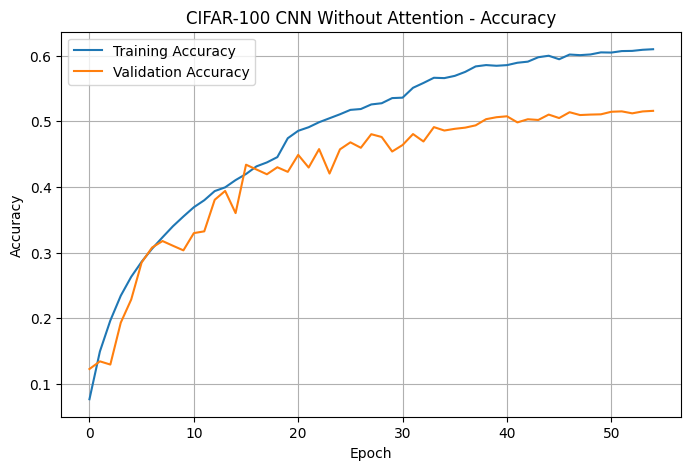

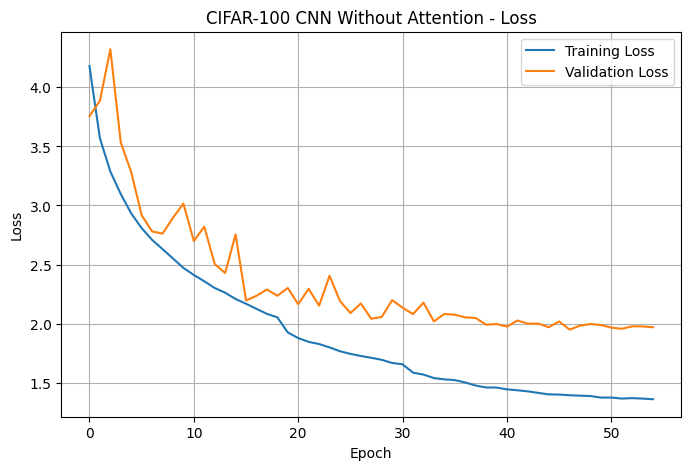

In [ ]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# MODEL 5: CIFAR-100 CNN WITHOUT ATTENTION
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_cifar100_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cifar100_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CIFAR-100 CNN Without Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_cifar100_cnn.history["loss"], label="Training Loss")
plt.plot(history_cifar100_cnn.history["val_loss"], label="Validation Loss")
plt.title("CIFAR-100 CNN Without Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# =========================
# PART 7: EVALUATE OFFICIAL CIFAR-100 TEST SET
# =========================

official_test_loss_cifar100_cnn, official_test_accuracy_cifar100_cnn = model_cifar100_cnn.evaluate(
    x_test_cifar100,
    y_test_cifar100,
    verbose=1
)

print("Official CIFAR-100 Test Loss:", official_test_loss_cifar100_cnn)
print("Official CIFAR-100 Test Accuracy:", official_test_accuracy_cifar100_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5150 - loss: 1.9691
Official CIFAR-100 Test Loss: 1.9691236019134521
Official CIFAR-100 Test Accuracy: 0.5149999856948853


In [ ]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_cifar100_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/Cifar100"

# Folder name mapped to official CIFAR-100 fine-label index
cifar100_folder_label_map = {
    "Apple": 0,
    "Baby": 2,
    "Bear": 3,
    "Bicycle": 8,
    "Bottle": 9,
    "Bus": 13,
    "Castle": 17,
    "Chair": 20,
    "Clock": 22,
    "Tiger": 88
}

external_images_cifar100 = []
external_labels_cifar100 = []

for folder_name, label in cifar100_folder_label_map.items():
    folder_path = os.path.join(external_cifar100_path, folder_name)

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            image_path = os.path.join(folder_path, filename)

            # CIFAR-100 expects RGB images resized to 32x32
            img = Image.open(image_path).convert("RGB").resize((32, 32))

            img_array = np.array(img).astype("float32") / 255.0

            external_images_cifar100.append(img_array)
            external_labels_cifar100.append(label)

external_images_cifar100 = np.array(external_images_cifar100)
external_labels_cifar100 = np.array(external_labels_cifar100)

print("External CIFAR-100 Images Shape:", external_images_cifar100.shape)
print("External CIFAR-100 Labels Shape:", external_labels_cifar100.shape)
print("Total External Images Loaded:", len(external_images_cifar100))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
External CIFAR-100 Images Shape: (54, 32, 32, 3)
External CIFAR-100 Labels Shape: (54,)
Total External Images Loaded: 54


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
External Testing Accuracy: 0.5555555555555556
Average Confidence Score: 71.34%


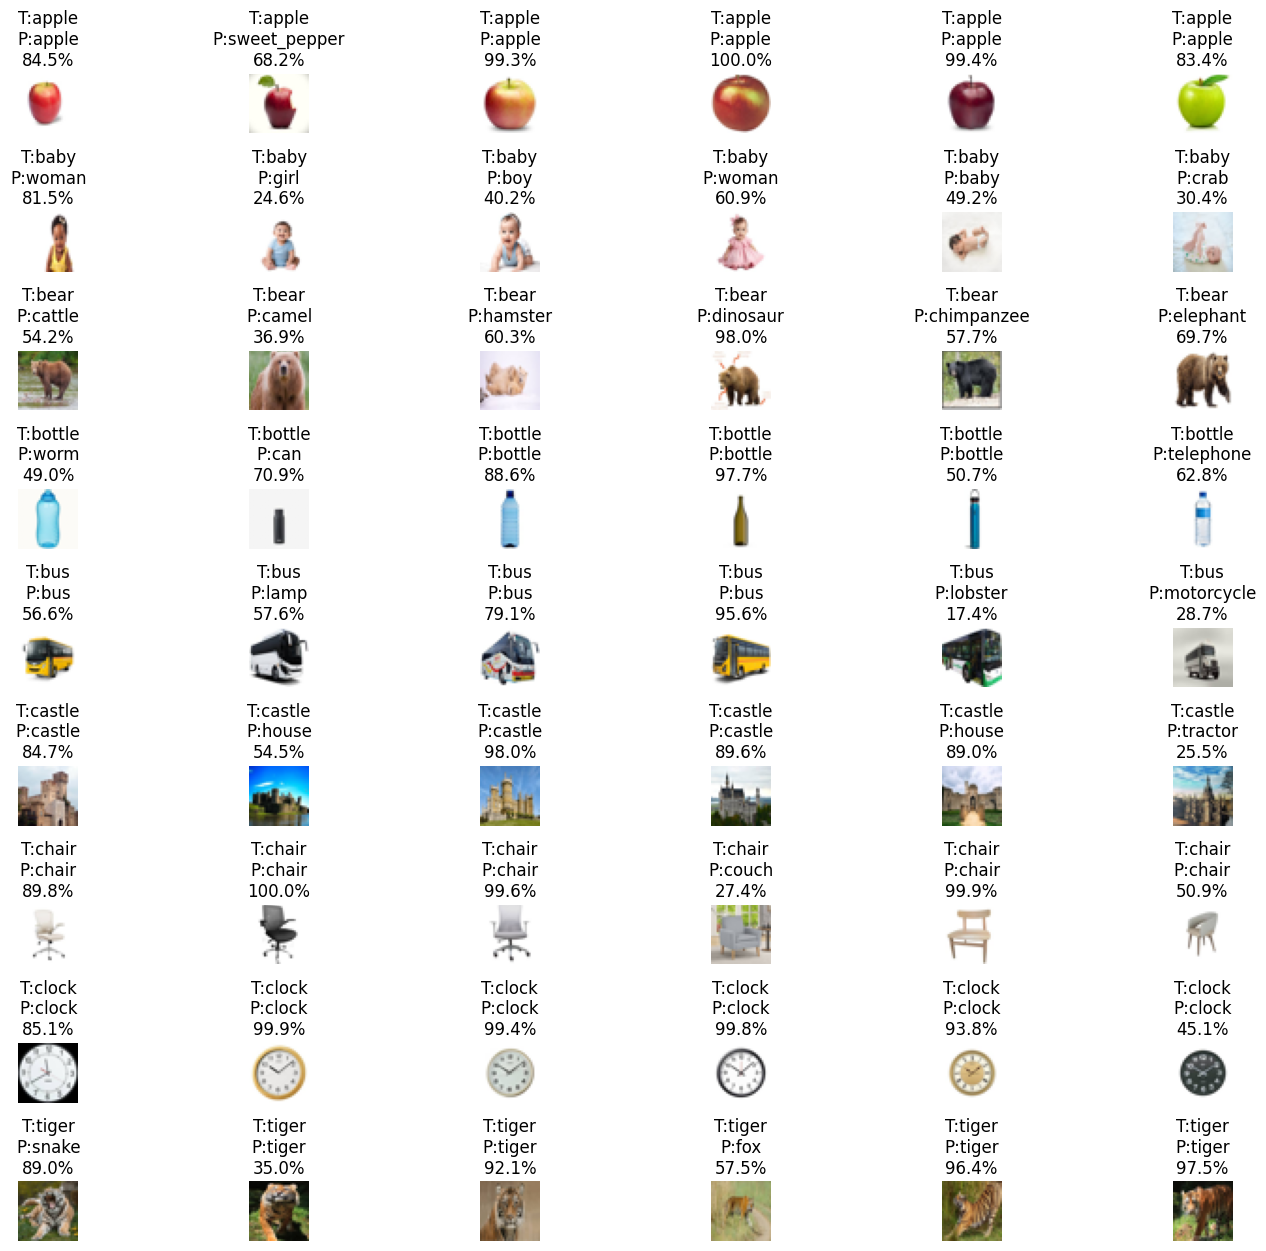

In [ ]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_cifar100_cnn = model_cifar100_cnn.predict(external_images_cifar100)

external_predicted_labels_cifar100_cnn = np.argmax(
    external_predictions_cifar100_cnn,
    axis=1
)

external_confidence_scores_cifar100_cnn = np.max(
    external_predictions_cifar100_cnn,
    axis=1
)

external_testing_accuracy_cifar100_cnn = accuracy_score(
    external_labels_cifar100,
    external_predicted_labels_cifar100_cnn
)

average_confidence_cifar100_cnn = np.mean(external_confidence_scores_cifar100_cnn) * 100

print("External Testing Accuracy:", external_testing_accuracy_cifar100_cnn)
print(f"Average Confidence Score: {average_confidence_cifar100_cnn:.2f}%")

# Display external predictions
num_images = len(external_images_cifar100)

plt.figure(figsize=(14, 14))

for i in range(num_images):
    plt.subplot(10, 6, i + 1)

    plt.imshow(external_images_cifar100[i])

    true_label = class_names_cifar100[external_labels_cifar100[i]]
    predicted_label = class_names_cifar100[external_predicted_labels_cifar100_cnn[i]]
    confidence = external_confidence_scores_cifar100_cnn[i] * 100

    plt.title(
        f"T:{true_label}\nP:{predicted_label}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

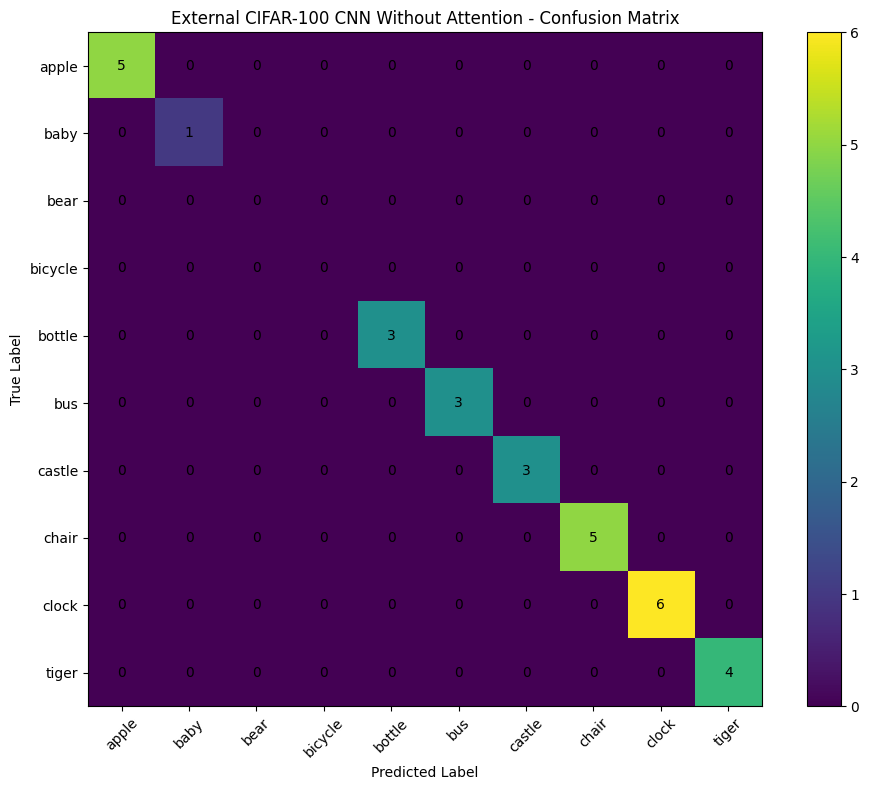


External CIFAR-100 CNN Without Attention - Classification Report:
              precision    recall  f1-score   support

       apple       1.00      0.83      0.91         6
        baby       1.00      0.17      0.29         6
        bear       0.00      0.00      0.00         6
     bicycle       0.00      0.00      0.00         0
      bottle       1.00      0.50      0.67         6
         bus       1.00      0.50      0.67         6
      castle       1.00      0.50      0.67         6
       chair       1.00      0.83      0.91         6
       clock       1.00      1.00      1.00         6
       tiger       1.00      0.67      0.80         6

   micro avg       1.00      0.56      0.71        54
   macro avg       0.80      0.50      0.59        54
weighted avg       0.89      0.56      0.66        54


Overall Model 5 Metrics:
Training Accuracy:          0.6100
Validation Accuracy:        0.5160
Best Validation Accuracy:   0.5160
Official Test Accuracy:     0.5150
External

In [ ]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# =========================

selected_cifar100_label_ids = list(cifar100_folder_label_map.values())

selected_class_names_cifar100 = [
    class_names_cifar100[label]
    for label in selected_cifar100_label_ids
]

external_conf_matrix_cifar100_cnn = confusion_matrix(
    external_labels_cifar100,
    external_predicted_labels_cifar100_cnn,
    labels=selected_cifar100_label_ids
)

plt.figure(figsize=(10, 8))
plt.imshow(external_conf_matrix_cifar100_cnn, interpolation="nearest")
plt.title("External CIFAR-100 CNN Without Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(selected_class_names_cifar100))
plt.xticks(tick_marks, selected_class_names_cifar100, rotation=45)
plt.yticks(tick_marks, selected_class_names_cifar100)

for i in range(external_conf_matrix_cifar100_cnn.shape[0]):
    for j in range(external_conf_matrix_cifar100_cnn.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_cifar100_cnn[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal CIFAR-100 CNN Without Attention - Classification Report:")
print(
    classification_report(
        external_labels_cifar100,
        external_predicted_labels_cifar100_cnn,
        labels=selected_cifar100_label_ids,
        target_names=selected_class_names_cifar100,
        zero_division=0
    )
)

external_precision_cifar100_cnn = precision_score(
    external_labels_cifar100,
    external_predicted_labels_cifar100_cnn,
    average="weighted",
    zero_division=0
)

external_recall_cifar100_cnn = recall_score(
    external_labels_cifar100,
    external_predicted_labels_cifar100_cnn,
    average="weighted",
    zero_division=0
)

external_f1_cifar100_cnn = f1_score(
    external_labels_cifar100,
    external_predicted_labels_cifar100_cnn,
    average="weighted",
    zero_division=0
)

print("\nOverall Model 5 Metrics:")
print(f"Training Accuracy:          {final_training_accuracy_cifar100_cnn:.4f}")
print(f"Validation Accuracy:        {final_validation_accuracy_cifar100_cnn:.4f}")
print(f"Best Validation Accuracy:   {best_validation_accuracy_cifar100_cnn:.4f}")
print(f"Official Test Accuracy:     {official_test_accuracy_cifar100_cnn:.4f}")
print(f"External Testing Accuracy:  {external_testing_accuracy_cifar100_cnn:.4f}")
print(f"Precision:                  {external_precision_cifar100_cnn:.4f}")
print(f"Recall:                     {external_recall_cifar100_cnn:.4f}")
print(f"F1-Score:                   {external_f1_cifar100_cnn:.4f}")
print(f"Average Confidence:         {average_confidence_cifar100_cnn:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_cifar100_cnn_pickle_path = os.path.join(
    model_save_folder,
    "model_cifar100_cnn_without_attention_deep.pkl"
)

with open(model_cifar100_cnn_pickle_path, "wb") as file:
    pickle.dump(model_cifar100_cnn, file)

print("Model 5 saved successfully as pickle file.")
print("Saved path:", model_cifar100_cnn_pickle_path)

**Cifar100 With Attention**  
The following models is a standard CNN with attention.

In [ ]:
# =========================
# MODEL 6: CIFAR-100 CNN WITH ATTENTION
# PART 1: LOAD AND CHECK DATASET
# =========================

(x_train_cifar100_att, y_train_cifar100_att), (x_test_cifar100_att, y_test_cifar100_att) = cifar100.load_data(label_mode="fine")

print("CIFAR-100 Training Images Shape:", x_train_cifar100_att.shape)
print("CIFAR-100 Training Labels Shape:", y_train_cifar100_att.shape)
print("CIFAR-100 Official Test Images Shape:", x_test_cifar100_att.shape)
print("CIFAR-100 Official Test Labels Shape:", y_test_cifar100_att.shape)

CIFAR-100 Training Images Shape: (50000, 32, 32, 3)
CIFAR-100 Training Labels Shape: (50000, 1)
CIFAR-100 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-100 Official Test Labels Shape: (10000, 1)


In [ ]:
# =========================
# PART 2: PREPROCESS DATASET
# =========================

x_train_cifar100_att = x_train_cifar100_att.astype("float32") / 255.0
x_test_cifar100_att = x_test_cifar100_att.astype("float32") / 255.0

y_train_cifar100_att = y_train_cifar100_att.flatten()
y_test_cifar100_att = y_test_cifar100_att.flatten()

print("After preprocessing:")
print("CIFAR-100 Training Images Shape:", x_train_cifar100_att.shape)
print("CIFAR-100 Training Labels Shape:", y_train_cifar100_att.shape)
print("CIFAR-100 Official Test Images Shape:", x_test_cifar100_att.shape)
print("CIFAR-100 Official Test Labels Shape:", y_test_cifar100_att.shape)
print("Minimum Pixel Value:", x_train_cifar100_att.min())
print("Maximum Pixel Value:", x_train_cifar100_att.max())

After preprocessing:
CIFAR-100 Training Images Shape: (50000, 32, 32, 3)
CIFAR-100 Training Labels Shape: (50000,)
CIFAR-100 Official Test Images Shape: (10000, 32, 32, 3)
CIFAR-100 Official Test Labels Shape: (10000,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [ ]:
# =========================
# PART 3: DEFINE CLASS NAMES
# =========================

class_names_cifar100 = [
    "apple", "aquarium_fish", "baby", "bear", "beaver",
    "bed", "bee", "beetle", "bicycle", "bottle",
    "bowl", "boy", "bridge", "bus", "butterfly",
    "camel", "can", "castle", "caterpillar", "cattle",
    "chair", "chimpanzee", "clock", "cloud", "cockroach",
    "couch", "crab", "crocodile", "cup", "dinosaur",
    "dolphin", "elephant", "flatfish", "forest", "fox",
    "girl", "hamster", "house", "kangaroo", "keyboard",
    "lamp", "lawn_mower", "leopard", "lion", "lizard",
    "lobster", "man", "maple_tree", "motorcycle", "mountain",
    "mouse", "mushroom", "oak_tree", "orange", "orchid",
    "otter", "palm_tree", "pear", "pickup_truck", "pine_tree",
    "plain", "plate", "poppy", "porcupine", "possum",
    "rabbit", "raccoon", "ray", "road", "rocket",
    "rose", "sea", "seal", "shark", "shrew",
    "skunk", "skyscraper", "snail", "snake", "spider",
    "squirrel", "streetcar", "sunflower", "sweet_pepper", "table",
    "tank", "telephone", "television", "tiger", "tractor",
    "train", "trout", "tulip", "turtle", "wardrobe",
    "whale", "willow_tree", "wolf", "woman", "worm"
]

In [ ]:
# =========================
# PART 4: BUILD AND COMPILE MODEL
# CNN WITH ATTENTION
# =========================

input_shape_cifar100 = (32, 32, 3)
num_classes_cifar100 = 100

data_augmentation_cifar100_attention = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

inputs = tf.keras.Input(shape=input_shape_cifar100)

x = data_augmentation_cifar100_attention(inputs)

# Block 1
x = layers.Conv2D(32, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(32, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.2)(x)

# Block 2
x = layers.Conv2D(64, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(64, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.3)(x)

# Block 3
x = layers.Conv2D(128, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(128, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.4)(x)

# Block 4
x = layers.Conv2D(256, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(256, (3, 3), padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# Attention block
# Current feature map shape is approximately 4x4x256.
# Reshape it into sequence format: 16 tokens with 256 features each.
x = layers.Reshape((-1, x.shape[-1]))(x)

query = x
key = x
value = x

attention_layer = layers.Attention(use_scale=True)
attn_output = attention_layer([query, value, key])

# Combine original CNN features with attention-enhanced features
x = layers.Concatenate()([x, attn_output])

# Classifier
x = layers.Flatten()(x)

x = layers.Dense(512)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(num_classes_cifar100, activation="softmax")(x)

model_cifar100_attention = models.Model(inputs=inputs, outputs=outputs)

model_cifar100_attention.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cifar100_attention.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_14      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 32, 32, 3) │          0 │ input_layer_14[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_56 (Conv2D)  │ (None, 32, 32,    │        896 │ sequential_7[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_56[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_63       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 32, 32,    │      9,248 │ activation_63[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_57[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_64       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_21    │ (None, 16, 16,    │          0 │ activation_64[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_29          │ (None, 16, 16,    │          0 │ max_pooling2d_21… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_58 (Conv2D)  │ (None, 16, 16,    │     18,496 │ dropout_29[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_58[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_65       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 16, 16,    │     36,928 │ activation_65[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_59[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_66       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_22    │ (None, 8, 8, 64)  │          0 │ activation_66[0]

 Total params: 5,424,261 (20.69 MB)

 Trainable params: 5,421,317 (20.68 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [ ]:
# =========================
# PART 5: TRAIN MODEL WITH EARLY STOPPING AND REDUCELRONPLATEAU
# =========================

early_stopping_cifar100_attention = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr_cifar100_attention = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_cifar100_attention = model_cifar100_attention.fit(
    x_train_cifar100_att,
    y_train_cifar100_att,
    epochs=60,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping_cifar100_attention, reduce_lr_cifar100_attention],
    verbose=1
)

final_training_accuracy_cifar100_attention = history_cifar100_attention.history["accuracy"][-1]
final_validation_accuracy_cifar100_attention = history_cifar100_attention.history["val_accuracy"][-1]
best_validation_accuracy_cifar100_attention = max(history_cifar100_attention.history["val_accuracy"])

print("Final Training Accuracy:", final_training_accuracy_cifar100_attention)
print("Final Validation Accuracy:", final_validation_accuracy_cifar100_attention)
print("Best Validation Accuracy:", best_validation_accuracy_cifar100_attention)

Epoch 1/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.0744 - loss: 4.1823 - val_accuracy: 0.1162 - val_loss: 3.9004 - learning_rate: 0.0010
Epoch 2/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.1468 - loss: 3.6023 - val_accuracy: 0.1561 - val_loss: 3.6238 - learning_rate: 0.0010
Epoch 3/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.1942 - loss: 3.3078 - val_accuracy: 0.1715 - val_loss: 3.5452 - learning_rate: 0.0010
Epoch 4/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.2275 - loss: 3.1113 - val_accuracy: 0.2137 - val_loss: 3.2240 - learning_rate: 0.0010
Epoch 5/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.2568 - loss: 2.9580 - val_accuracy: 0.2000 - val_loss: 3.4543 - learning_rate: 0.0010
Epoch 6/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.2806 - loss: 2.8244 - val_accuracy: 0.2461 - val_loss: 3.2227 - learning_rate: 0.0010
Epoch 7/60
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.3012 - l

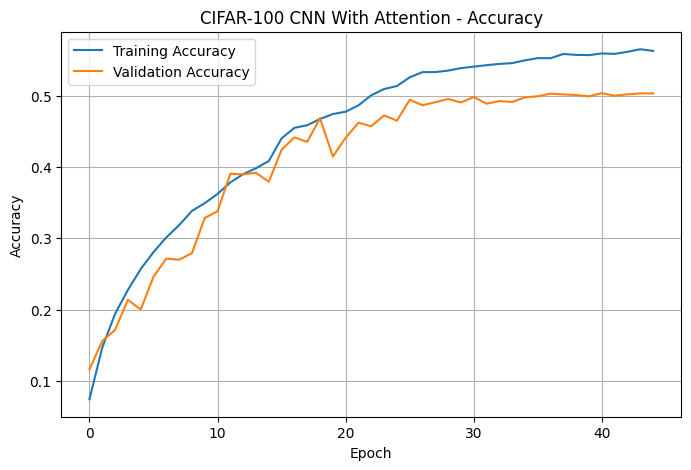

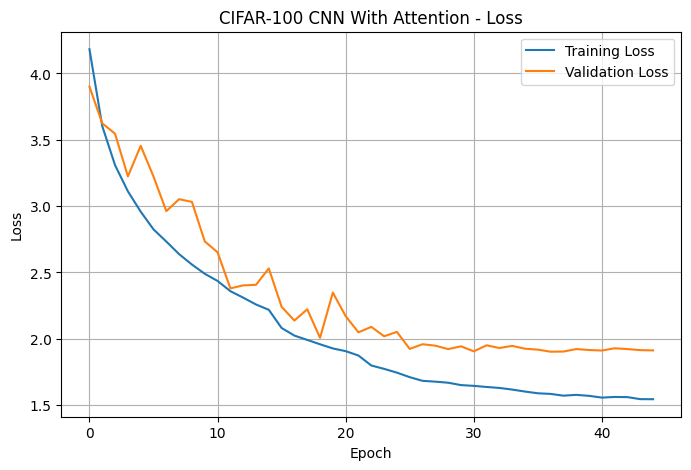

In [ ]:
# =========================
# PART 6: ACCURACY AND LOSS GRAPHS
# MODEL 6: CIFAR-100 CNN WITH ATTENTION
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history_cifar100_attention.history["accuracy"], label="Training Accuracy")
plt.plot(history_cifar100_attention.history["val_accuracy"], label="Validation Accuracy")
plt.title("CIFAR-100 CNN With Attention - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_cifar100_attention.history["loss"], label="Training Loss")
plt.plot(history_cifar100_attention.history["val_loss"], label="Validation Loss")
plt.title("CIFAR-100 CNN With Attention - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# =========================
# PART 7: EVALUATE OFFICIAL CIFAR-100 TEST SET
# =========================

official_test_loss_cifar100_attention, official_test_accuracy_cifar100_attention = model_cifar100_attention.evaluate(
    x_test_cifar100_att,
    y_test_cifar100_att,
    verbose=1
)

print("Official CIFAR-100 Test Loss:", official_test_loss_cifar100_attention)
print("Official CIFAR-100 Test Accuracy:", official_test_accuracy_cifar100_attention)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5145 - loss: 1.8726
Official CIFAR-100 Test Loss: 1.8726191520690918
Official CIFAR-100 Test Accuracy: 0.5145000219345093


In [ ]:
# =========================
# PART 8: LOAD EXTERNAL DRIVE TEST IMAGES
# =========================

drive.mount("/content/drive")

external_cifar100_path = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/Cifar100"

cifar100_folder_label_map = {
    "Apple": 0,
    "Baby": 2,
    "Bear": 3,
    "Bicycle": 8,
    "Bottle": 9,
    "Bus": 13,
    "Castle": 17,
    "Chair": 20,
    "Clock": 22,
    "Tiger": 88
}

external_images_cifar100_attention = []
external_labels_cifar100_attention = []

for folder_name, label in cifar100_folder_label_map.items():
    folder_path = os.path.join(external_cifar100_path, folder_name)

    if not os.path.exists(folder_path):
        print(f"Warning: Folder not found: {folder_path}")
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            image_path = os.path.join(folder_path, filename)

            img = Image.open(image_path).convert("RGB").resize((32, 32))
            img_array = np.array(img).astype("float32") / 255.0

            external_images_cifar100_attention.append(img_array)
            external_labels_cifar100_attention.append(label)

external_images_cifar100_attention = np.array(external_images_cifar100_attention)
external_labels_cifar100_attention = np.array(external_labels_cifar100_attention)

print("External CIFAR-100 Images Shape:", external_images_cifar100_attention.shape)
print("External CIFAR-100 Labels Shape:", external_labels_cifar100_attention.shape)
print("Total External Images Loaded:", len(external_images_cifar100_attention))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
External CIFAR-100 Images Shape: (54, 32, 32, 3)
External CIFAR-100 Labels Shape: (54,)
Total External Images Loaded: 54


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 296ms/step
External Testing Accuracy: 0.6666666666666666
Average Confidence Score: 70.29%


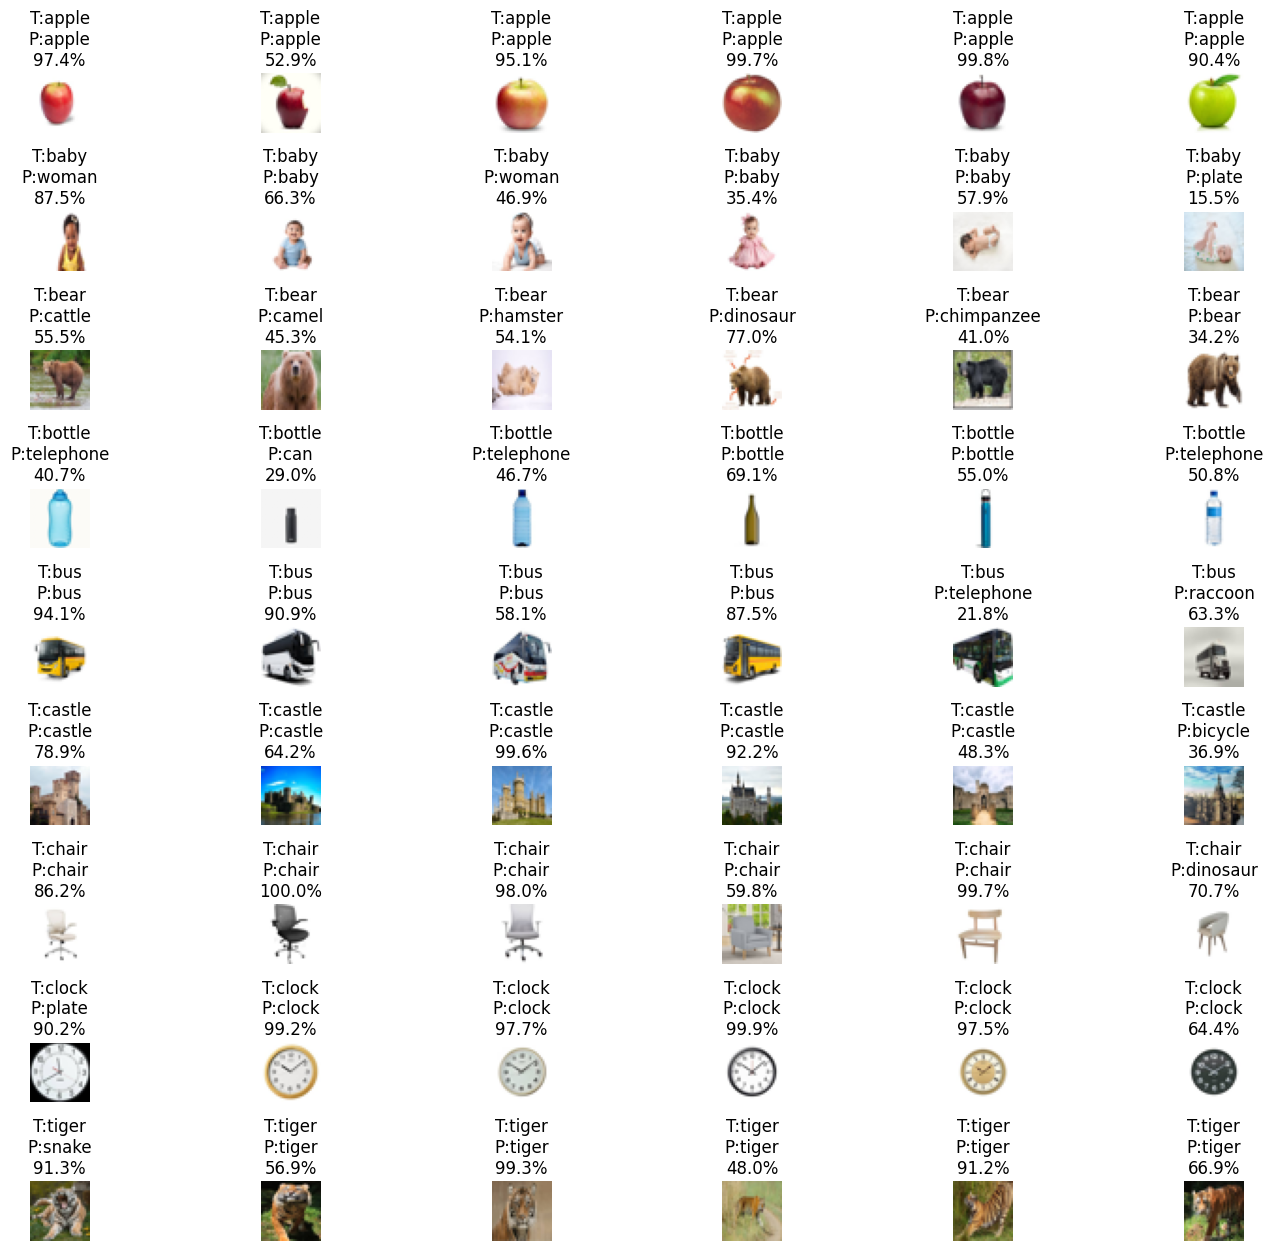

In [ ]:
# =========================
# PART 9: EXTERNAL TESTING ACCURACY AND CONFIDENCE TEST
# =========================

external_predictions_cifar100_attention = model_cifar100_attention.predict(
    external_images_cifar100_attention
)

external_predicted_labels_cifar100_attention = np.argmax(
    external_predictions_cifar100_attention,
    axis=1
)

external_confidence_scores_cifar100_attention = np.max(
    external_predictions_cifar100_attention,
    axis=1
)

external_testing_accuracy_cifar100_attention = accuracy_score(
    external_labels_cifar100_attention,
    external_predicted_labels_cifar100_attention
)

average_confidence_cifar100_attention = np.mean(
    external_confidence_scores_cifar100_attention
) * 100

print("External Testing Accuracy:", external_testing_accuracy_cifar100_attention)
print(f"Average Confidence Score: {average_confidence_cifar100_attention:.2f}%")

num_images = len(external_images_cifar100_attention)

plt.figure(figsize=(14, 14))

for i in range(num_images):
    plt.subplot(10, 6, i + 1)

    plt.imshow(external_images_cifar100_attention[i])

    true_label = class_names_cifar100[external_labels_cifar100_attention[i]]
    predicted_label = class_names_cifar100[external_predicted_labels_cifar100_attention[i]]
    confidence = external_confidence_scores_cifar100_attention[i] * 100

    plt.title(
        f"T:{true_label}\nP:{predicted_label}\n"
        f"{confidence:.1f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

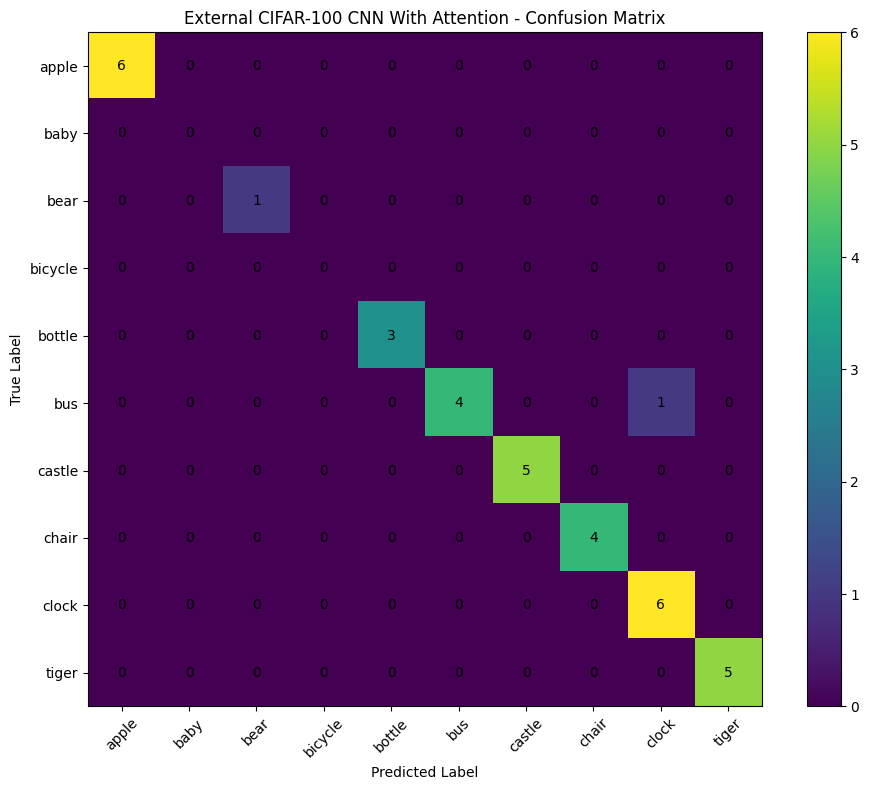


External CIFAR-100 CNN With Attention - Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00         6
        baby       0.00      0.00      0.00         6
        bear       1.00      0.17      0.29         6
     bicycle       0.00      0.00      0.00         0
      bottle       1.00      0.50      0.67         6
         bus       1.00      0.67      0.80         6
      castle       1.00      0.83      0.91         6
       chair       1.00      0.67      0.80         6
       clock       0.86      1.00      0.92         6
       tiger       1.00      0.83      0.91         6

   micro avg       0.97      0.63      0.76        54
   macro avg       0.79      0.57      0.63        54
weighted avg       0.87      0.63      0.70        54


Overall Model 6 Metrics:
Training Accuracy:          0.5734
Validation Accuracy:        0.5201
Best Validation Accuracy:   0.5201
Official Test Accuracy:     0.5236
External Te

In [ ]:
# =========================
# PART 10: METRICS, CONFUSION MATRIX, AND DUMP MODEL
# =========================

selected_cifar100_label_ids = list(cifar100_folder_label_map.values())

selected_class_names_cifar100 = [
    class_names_cifar100[label]
    for label in selected_cifar100_label_ids
]

external_conf_matrix_cifar100_attention = confusion_matrix(
    external_labels_cifar100_attention,
    external_predicted_labels_cifar100_attention,
    labels=selected_cifar100_label_ids
)

plt.figure(figsize=(10, 8))
plt.imshow(external_conf_matrix_cifar100_attention, interpolation="nearest")
plt.title("External CIFAR-100 CNN With Attention - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

tick_marks = np.arange(len(selected_class_names_cifar100))
plt.xticks(tick_marks, selected_class_names_cifar100, rotation=45)
plt.yticks(tick_marks, selected_class_names_cifar100)

for i in range(external_conf_matrix_cifar100_attention.shape[0]):
    for j in range(external_conf_matrix_cifar100_attention.shape[1]):
        plt.text(
            j,
            i,
            external_conf_matrix_cifar100_attention[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

print("\nExternal CIFAR-100 CNN With Attention - Classification Report:")
print(
    classification_report(
        external_labels_cifar100_attention,
        external_predicted_labels_cifar100_attention,
        labels=selected_cifar100_label_ids,
        target_names=selected_class_names_cifar100,
        zero_division=0
    )
)

external_precision_cifar100_attention = precision_score(
    external_labels_cifar100_attention,
    external_predicted_labels_cifar100_attention,
    average="weighted",
    zero_division=0
)

external_recall_cifar100_attention = recall_score(
    external_labels_cifar100_attention,
    external_predicted_labels_cifar100_attention,
    average="weighted",
    zero_division=0
)

external_f1_cifar100_attention = f1_score(
    external_labels_cifar100_attention,
    external_predicted_labels_cifar100_attention,
    average="weighted",
    zero_division=0
)

print("\nOverall Model 6 Metrics:")
print(f"Training Accuracy:          {final_training_accuracy_cifar100_attention:.4f}")
print(f"Validation Accuracy:        {final_validation_accuracy_cifar100_attention:.4f}")
print(f"Best Validation Accuracy:   {best_validation_accuracy_cifar100_attention:.4f}")
print(f"Official Test Accuracy:     {official_test_accuracy_cifar100_attention:.4f}")
print(f"External Testing Accuracy:  {external_testing_accuracy_cifar100_attention:.4f}")
print(f"Precision:                  {external_precision_cifar100_attention:.4f}")
print(f"Recall:                     {external_recall_cifar100_attention:.4f}")
print(f"F1-Score:                   {external_f1_cifar100_attention:.4f}")
print(f"Average Confidence:         {average_confidence_cifar100_attention:.2f}%")

# Save model as pickle file to Google Drive
model_save_folder = "/content/drive/MyDrive/CS190-4P/6ModelsCNN/SavedModels"
os.makedirs(model_save_folder, exist_ok=True)

model_cifar100_attention_pickle_path = os.path.join(
    model_save_folder,
    "model_cifar100_cnn_with_attention.pkl"
)

with open(model_cifar100_attention_pickle_path, "wb") as file:
    pickle.dump(model_cifar100_attention, file)

print("Model 6 saved successfully as pickle file.")
print("Saved path:", model_cifar100_attention_pickle_path)

**FInal Comparisons**  
The following table represents all the comparisons of models with attention and without attention.

In [25]:
# =========================
# PAIRWISE COMPARISON BY DATASET
# =========================
import pandas as pd

pairwise_comparison = pd.DataFrame({
    "Dataset": [
        "MNIST",
        "CIFAR-10",
        "CIFAR-100"
    ],

    "Without Attention Model": [
        "Model 1",
        "Model 3",
        "Model 5"
    ],

    "With Attention Model": [
        "Model 2",
        "Model 4",
        "Model 6"
    ],

    "Without Attention External Accuracy": [
        external_testing_accuracy_mnist_cnn,
        external_testing_accuracy_cifar10_cnn,
        external_testing_accuracy_cifar100_cnn
    ],

    "With Attention External Accuracy": [
        external_testing_accuracy_mnist_attention,
        external_testing_accuracy_cifar10_attention,
        external_testing_accuracy_cifar100_attention
    ],

    "Without Attention F1-Score": [
        external_f1_mnist_cnn,
        external_f1_cifar10_cnn,
        external_f1_cifar100_cnn
    ],

    "With Attention F1-Score": [
        external_f1_mnist_attention,
        external_f1_cifar10_attention,
        external_f1_cifar100_attention
    ],

    "Without Attention Confidence": [
        average_confidence_mnist_cnn,
        average_confidence_cifar10_cnn,
        average_confidence_cifar100_cnn
    ],

    "With Attention Confidence": [
        average_confidence_mnist_attention,
        average_confidence_cifar10_attention,
        average_confidence_cifar100_attention
    ]
})

pairwise_comparison["Better Model Based on External Accuracy"] = pairwise_comparison.apply(
    lambda row: row["Without Attention Model"]
    if row["Without Attention External Accuracy"] > row["With Attention External Accuracy"]
    else row["With Attention Model"],
    axis=1
)

pairwise_comparison = pairwise_comparison.round(4)

pairwise_comparison

NameError: name 'external_testing_accuracy_cifar10_cnn' is not defined